# Práctica 4 — *Transfer learning*: clasificar MNIST con redes preentrenadas

## Objetivos

En la práctica 3 se diseñaron y entrenaron redes convolucionales **desde cero**. En esta práctica se aplica **aprendizaje por transferencia** (*transfer learning*): se reutilizan redes ya entrenadas en ImageNet —AlexNet, VGG16, VGG19, GoogLeNet, ResNet50 y DenseNet121— para clasificar los mismos dígitos MNIST. Se implementa en **PyTorch + torchvision** ejecutándose en la GPU del equipo (Metal Performance Shaders): la instalación de TensorFlow disponible solo funciona en CPU y `tensorflow-metal` está abandonado (no hay paquetes para TensorFlow ≥ 2.18 / Python 3.13), mientras que PyTorch sí acelera en este hardware —el mismo código también funcionaría en CUDA o en CPU, como en Colab—. Se comparan veintiséis propuestas que combinan:

- **extracción de características**: la red preentrenada se congela y actúa como extractor fijo; solo se entrena una pequeña cabeza clasificadora (lineal o MLP) sobre los vectores de características;
- **ajuste fino (*fine-tuning*)**: se descongelan las últimas capas convolucionales (o toda la base) y se continúa el entrenamiento con una tasa de aprendizaje diez veces menor;
- dos **resoluciones de entrada** (32 y 64 píxeles) y un **control con pesos aleatorios** que aísla el valor del preentrenamiento en ImageNet;
- como referencia, la **mejor CNN de la práctica 3**, entrenada desde cero sobre exactamente la misma partición (no participa en la selección).

Como en las prácticas anteriores, la mejor configuración se elige **exclusivamente con validación** y el test se reserva para la estimación final. El mejor modelo se exporta a disco para futuro uso.

In [1]:
import copy
import gc
import os
import time
import urllib.request
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name != 'Practica-4' and (BASE_DIR / 'Practica-4').is_dir():
    BASE_DIR = BASE_DIR / 'Practica-4'
PRACTICA3_DIR = BASE_DIR.parent / 'Practica-3'
os.environ['TORCH_HOME'] = str(BASE_DIR / '.torch')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models

SEED = 42
BATCH_SIZE = 128
PREDICT_BATCH_SIZE = 256
MAX_EPOCHS_HEAD = 30
PATIENCE_HEAD = 3
MAX_EPOCHS_FT = 5
PATIENCE_FT = 2
LR_HEAD = 1e-3
LR_FT = 1e-4
CLASSES = np.arange(10)

if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')


def sync():
    if device.type == 'mps':
        torch.mps.synchronize()
    elif device.type == 'cuda':
        torch.cuda.synchronize()


torch.manual_seed(SEED)
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
np.set_printoptions(linewidth=140)
print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('Dispositivo:', device)

PyTorch: 2.14.1 | torchvision: 0.29.1
Dispositivo: mps


## 1. Datos, separación y preprocesamiento

Se usa exactamente la misma partición que en las prácticas anteriores: de las 60 000 imágenes de entrenamiento de MNIST se apartan **600 imágenes de cada dígito** (6 000 en total) como validación estratificada con la misma semilla; las 54 000 restantes ajustan los pesos y las 10 000 oficiales forman el test. No existe solapamiento entre los tres conjuntos. Los píxeles se escalan a $[0,1]$ y cada imagen queda como tensor `(1, 28, 28)` (formato *channels-first* de PyTorch).

La particularidad de esta práctica es que las redes preentrenadas esperan imágenes **a color**, de **mayor resolución** que un dígito MNIST y normalizadas con la media y desviación de ImageNet. Esa adaptación no se hace sobre los datos sino **dentro del propio modelo** (sección 2), de modo que todos los modelos —incluido el que se exporte a disco— reciben la misma entrada `(n, 1, 28, 28)` en $[0,1]$ de siempre.

Entrenamiento forma=(54000, 1, 28, 28) rango=[0.0, 1.0] por clase=[5323 6142 5358 5531 5242 4821 5318 5665 5251 5349]
Validación    forma=(6000, 1, 28, 28) rango=[0.0, 1.0] por clase=[600 600 600 600 600 600 600 600 600 600]
Test          forma=(10000, 1, 28, 28) rango=[0.0, 1.0] por clase=[ 980 1135 1032 1010  982  892  958 1028  974 1009]


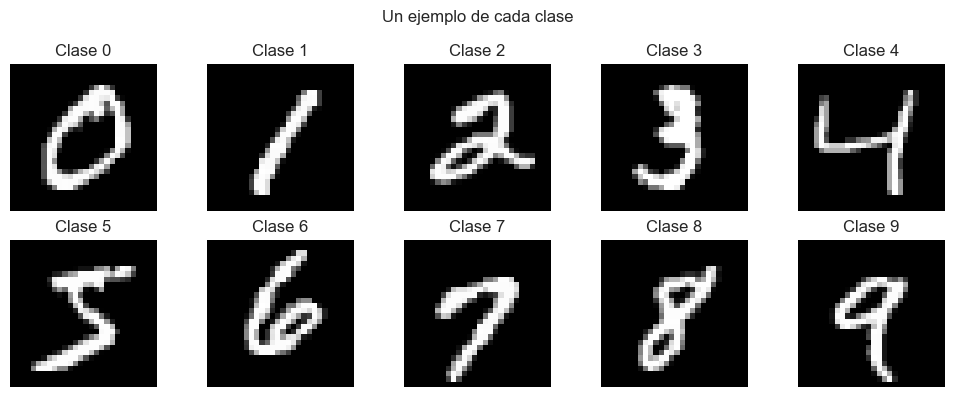

In [2]:
MNIST_PATH = BASE_DIR / '.keras' / 'datasets' / 'mnist.npz'
if not MNIST_PATH.exists():
    MNIST_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', MNIST_PATH)
with np.load(MNIST_PATH) as mnist:
    images_train, digits_train = mnist['x_train'].copy(), mnist['y_train'].copy()
    images_test, digits_test = mnist['x_test'].copy(), mnist['y_test'].copy()
if images_train.shape != (60_000, 28, 28) or images_test.shape != (10_000, 28, 28):
    raise ValueError('Dimensiones inesperadas en MNIST')
if not (np.isin(digits_train, CLASSES).all() and np.isin(digits_test, CLASSES).all()):
    raise ValueError('Las etiquetas deben representar dígitos entre 0 y 9')

rng = np.random.default_rng(SEED)
validation_indices = rng.permutation(np.concatenate([
    rng.permutation(np.flatnonzero(digits_train == digit))[:600] for digit in CLASSES
]))
fit_mask = np.ones(len(digits_train), dtype=bool)
fit_mask[validation_indices] = False

def preprocess(images):
    return torch.from_numpy(images.astype('float32') / 255.0)[:, None]

x_fit, y_fit = preprocess(images_train[fit_mask]), torch.from_numpy(digits_train[fit_mask].astype('int64'))
x_val, y_val = preprocess(images_train[validation_indices]), torch.from_numpy(digits_train[validation_indices].astype('int64'))
x_test, y_test = preprocess(images_test), torch.from_numpy(digits_test.astype('int64'))

for name, x, y in (('Entrenamiento', x_fit, y_fit), ('Validación', x_val, y_val), ('Test', x_test, y_test)):
    print(f'{name:<13} forma={tuple(x.shape)} rango=[{x.min():.1f}, {x.max():.1f}] por clase={np.bincount(y.numpy(), minlength=10)}')
assert len(x_fit) + len(x_val) == 60_000 and len(x_test) == 10_000
assert len(np.intersect1d(np.flatnonzero(fit_mask), validation_indices)) == 0

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in zip(CLASSES, axes.flat):
    ax.imshow(x_fit[np.flatnonzero(y_fit.numpy() == digit)[0], 0].numpy(), cmap='gray')
    ax.set_title(f'Clase {digit}')
    ax.axis('off')
plt.suptitle('Un ejemplo de cada clase')
plt.tight_layout()
plt.show()

## 2. Propuestas: extracción de características y ajuste fino

Las redes de `torchvision.models` se entrenaron en ImageNet: 1,2 millones de fotografías a color de 1 000 clases, normalmente a 224×224 píxeles. Sus primeras capas detectan bordes, texturas y formas genéricas que también describen los trazos de un dígito, de modo que los **pesos aprendidos se pueden reutilizar** en lugar de partir de una inicialización aleatoria. Todas se cargan con los pesos `IMAGENET1K_V1`, es decir, el entrenamiento clásico. Hay dos formas de hacerlo:

- **Extracción de características.** Se elimina el clasificador original y se congelan todos los pesos (`requires_grad = False`). Cada imagen se resume en un vector de características (256–2048 números, tras un *average pooling* global) sobre el que solo se entrena un clasificador pequeño. Como la base está congelada, las características se calculan **una sola vez** para todo el experimento y las cabezas se entrenan sobre los vectores guardados, lo que resulta muy barato.
- **Ajuste fino.** Partiendo de la cabeza ya entrenada (receta clásica en dos fases, para que los gradientes de una cabeza recién inicializada no destruyan los filtros aprendidos), se descongela el último bloque convolucional —ajuste *parcial*— o toda la base —ajuste *total*— y se sigue entrenando con una tasa pequeña (Adam $10^{-4}$): el ajuste debe ser sutil. Siguiendo la práctica recomendada, las capas **BatchNormalization permanecen congeladas y en modo evaluación** (`eval()`, reaplicado en cada época), para no contaminar las estadísticas aprendidas en ImageNet con lotes de dígitos.

**Adaptación de la entrada** (dentro del modelo, en el módulo `Preprocess`): la imagen `(1, 28, 28)` se redimensiona a `res × res` con interpolación bilineal, el canal de gris se **replica tres veces** para simular una imagen RGB y se estandariza con la media $[0{,}485,\ 0{,}456,\ 0{,}406]$ y desviación $[0{,}229,\ 0{,}224,\ 0{,}225]$ de ImageNet —la misma que usan todas las redes de torchvision—. GoogLeNet (Inception v1, vista en clase) aplica además su propia transformación interna `transform_input`, que precisamente espera esta normalización.

No todas las redes admiten entradas muy pequeñas: a 32×32 los mapas de características de AlexNet colapsan a 0 antes de llegar a su *pooling* final, por lo que solo se prueba a 64×64; el resto funciona a 32 px, y en ResNet50 y DenseNet121 se compara con 64 px. La tabla resume las veintiséis propuestas:

| # | Configuración | Base | Entrada | Pesos | Estrategia | Qué se estudia |
|:-:|:--|:--|:-:|:--|:--|:--|
| 1–2 | `vgg16-32-congelada-lineal` / `-mlp` | VGG16 | 32 px | ImageNet | congelada | cabeza **lineal frente a MLP** (como en todos los pares 3–18) |
| 3–4 | `vgg19-32-congelada-*` | VGG19 | 32 px | ImageNet | congelada | efecto de la **base** (frente a VGG16) |
| 5–6 | `resnet50-32-congelada-*` | ResNet50 | 32 px | ImageNet | congelada | base con conexiones residuales |
| 7–8 | `resnet50-64-congelada-*` | ResNet50 | 64 px | ImageNet | congelada | efecto de la **resolución** de entrada |
| 9–10 | `densenet121-32-congelada-*` | DenseNet121 | 32 px | ImageNet | congelada | base con conexiones densas |
| 11–12 | `densenet121-64-congelada-*` | DenseNet121 | 64 px | ImageNet | congelada | resolución (frente a 9–10) |
| 13–14 | `googlenet-32-congelada-*` | GoogLeNet | 32 px | ImageNet | congelada | módulos Inception v1 |
| 15–16 | `alexnet-64-congelada-*` | AlexNet | 64 px | ImageNet | congelada | la CNN que abrió la era moderna (2012) |
| 17–18 | `resnet50-32-aleatoria-*` | ResNet50 | 32 px | **aleatorios** | congelada | valor del **preentrenamiento** (frente a 5–6) |
| 19 | `vgg16-32-ft-parcial` | VGG16 | 32 px | ImageNet | ajuste fino último bloque | **congelada frente a ajuste parcial** |
| 20 | `vgg16-32-ft-total` | VGG16 | 32 px | ImageNet | ajuste fino completo | **parcial frente a total** |
| 21 | `resnet50-32-ft-parcial` | ResNet50 | 32 px | ImageNet | ajuste fino `layer4` | ajuste parcial en base residual |
| 22 | `resnet50-32-ft-total` | ResNet50 | 32 px | ImageNet | ajuste fino completo | parcial frente a total |
| 23 | `densenet121-32-ft-parcial` | DenseNet121 | 32 px | ImageNet | ajuste fino `denseblock4` | ajuste parcial en otra base |
| 24 | `densenet121-32-ft-total` | DenseNet121 | 32 px | ImageNet | ajuste fino completo | parcial frente a total |
| 25 | `densenet121-64-ft-total` | DenseNet121 | 64 px | ImageNet | ajuste fino completo | **resolución bajo ajuste fino** |
| 26 | `cnn-p3-desde-cero` † | CNN propia (P3) | 28 px | — | desde cero | **referencia**, no seleccionable |

Las comparaciones están pensadas por pares o trios que difieren en un único factor, igual que en la práctica 3.

In [3]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

WEIGHTS_ENUMS = {
    'alexnet': models.AlexNet_Weights.IMAGENET1K_V1,
    'vgg16': models.VGG16_Weights.IMAGENET1K_V1,
    'vgg19': models.VGG19_Weights.IMAGENET1K_V1,
    'googlenet': models.GoogLeNet_Weights.IMAGENET1K_V1,
    'resnet50': models.ResNet50_Weights.IMAGENET1K_V1,
    'densenet121': models.DenseNet121_Weights.IMAGENET1K_V1,
}

FEATURE_DIMS = {'alexnet': 256, 'vgg16': 512, 'vgg19': 512,
                'googlenet': 1024, 'resnet50': 2048, 'densenet121': 1024}


class Preprocess(nn.Module):
    def __init__(self, res):
        super().__init__()
        self.res = res
        self.register_buffer('mean', torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def forward(self, x):
        x = F.interpolate(x, size=(self.res, self.res), mode='bilinear', align_corners=False)
        x = x.expand(-1, 3, -1, -1)
        return (x - self.mean) / self.std


def build_backbone(name, weights):
    if weights == 'imagenet':
        weights = WEIGHTS_ENUMS[name]
    if name in ('alexnet', 'vgg16', 'vgg19'):
        net = getattr(models, name)(weights=weights)
        return nn.Sequential(net.features, nn.AdaptiveAvgPool2d(1), nn.Flatten(1))
    if name == 'googlenet':
        net = models.googlenet(weights=weights, aux_logits=weights is not None)
        net.aux_logits = False
        net.aux1 = None
        net.aux2 = None
        net.fc = nn.Identity()
        return net
    if name == 'resnet50':
        net = models.resnet50(weights=weights)
        net.fc = nn.Identity()
        return net
    if name == 'densenet121':
        net = models.densenet121(weights=weights)
        net.classifier = nn.Identity()
        return net
    raise ValueError(f'Base desconocida: {name}')


class Extractor(nn.Module):
    def __init__(self, res, backbone):
        super().__init__()
        self.pre = Preprocess(res)
        self.backbone = backbone

    def forward(self, x):
        return self.backbone(self.pre(x))


def build_extractor(backbone_name, res, weights='imagenet'):
    backbone = build_backbone(backbone_name, weights)
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    return Extractor(res, backbone)


def build_head(feature_dim, head):
    if head == 'lineal':
        return nn.Linear(feature_dim, 10)
    return nn.Sequential(
        nn.Linear(feature_dim, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 10))


class TransferModel(nn.Module):
    def __init__(self, extractor, head):
        super().__init__()
        self.extractor = extractor
        self.head = head

    def forward(self, x):
        return self.head(self.extractor(x))


def unfreeze_backbone(extractor, backbone_name, corte):
    backbone = extractor.backbone
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    if corte is None:
        for parameter in backbone.parameters():
            parameter.requires_grad_(True)
    elif backbone_name == 'vgg16':
        for parameter in backbone[0][24:].parameters():
            parameter.requires_grad_(True)
    elif backbone_name == 'resnet50':
        for parameter in backbone.layer4.parameters():
            parameter.requires_grad_(True)
    elif backbone_name == 'densenet121':
        for parameter in backbone.features.denseblock4.parameters():
            parameter.requires_grad_(True)
    else:
        raise ValueError(f'No hay punto de corte definido para {backbone_name}')
    for module in backbone.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            for parameter in module.parameters():
                parameter.requires_grad_(False)
            module.eval()


def count_parameters(model, trainable_only=False):
    return int(sum(p.numel() for p in model.parameters() if not trainable_only or p.requires_grad))


def freeze_bn_eval(model):
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


@torch.no_grad()
def forward_batches(model, x, dev, batch_size=512):
    model.eval()
    outputs = []
    for i in range(0, len(x), batch_size):
        outputs.append(model(x[i:i + batch_size].to(dev)).cpu())
    return torch.cat(outputs)


def evaluate_predictions(model, x, y, dev):
    predictions = forward_batches(model, x, dev).argmax(dim=1).numpy()
    y = np.asarray(y)
    matrix = np.zeros((10, 10), dtype=np.int64)
    np.add.at(matrix, (y, predictions), 1)
    errors = int(np.count_nonzero(predictions != y))
    accuracy = float(np.mean(predictions == y))
    if matrix.sum() != len(y) or errors != len(y) - np.trace(matrix):
        raise RuntimeError('Las métricas y la matriz de confusión no concuerdan')
    return accuracy, errors, matrix, predictions


def loss_and_accuracy(model, x, y, dev):
    logits = forward_batches(model, x, dev)
    labels = torch.as_tensor(np.asarray(y), dtype=torch.int64)
    return float(F.cross_entropy(logits, labels)), float((logits.argmax(dim=1) == labels).float().mean())


def fit(model, x_tr, y_tr, x_va, y_va, *, epochs, patience, lr):
    model.to(device)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    criterion = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(x_tr, y_tr), batch_size=BATCH_SIZE,
                        shuffle=True, generator=generator)
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_loss, best_state, best_epoch, waiting = np.inf, None, 0, 0
    for epoch in range(epochs):
        model.train()
        freeze_bn_eval(model)
        total_loss, correct = 0.0, 0
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x_batch)
            correct += int((logits.argmax(1) == y_batch).sum())
        val_loss, val_accuracy = loss_and_accuracy(model, x_va, y_va, device)
        history['loss'].append(total_loss / len(loader.dataset))
        history['accuracy'].append(correct / len(loader.dataset))
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_accuracy)
        if val_loss < best_loss:
            best_loss, best_epoch, waiting = val_loss, epoch, 0
            best_state = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
        else:
            waiting += 1
            if waiting >= patience:
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return history, epoch + 1, best_epoch + 1

In [4]:
EXTRACTORS = [
    {'key': 'vgg16-32-congelada',       'backbone': 'vgg16',       'res': 32, 'weights': 'imagenet'},
    {'key': 'vgg19-32-congelada',       'backbone': 'vgg19',       'res': 32, 'weights': 'imagenet'},
    {'key': 'resnet50-32-congelada',    'backbone': 'resnet50',    'res': 32, 'weights': 'imagenet'},
    {'key': 'resnet50-64-congelada',    'backbone': 'resnet50',    'res': 64, 'weights': 'imagenet'},
    {'key': 'densenet121-32-congelada', 'backbone': 'densenet121', 'res': 32, 'weights': 'imagenet'},
    {'key': 'densenet121-64-congelada', 'backbone': 'densenet121', 'res': 64, 'weights': 'imagenet'},
    {'key': 'googlenet-32-congelada',   'backbone': 'googlenet',   'res': 32, 'weights': 'imagenet'},
    {'key': 'alexnet-64-congelada',     'backbone': 'alexnet',     'res': 64, 'weights': 'imagenet'},
    {'key': 'resnet50-32-aleatoria',    'backbone': 'resnet50',    'res': 32, 'weights': None},
]

FT_CONFIGS = [
    {'name': 'vgg16-32-ft-parcial',       'backbone': 'vgg16',       'res': 32, 'strategy': 'ft-parcial', 'fuente': 'vgg16-32-congelada',       'corte': 'block5'},
    {'name': 'vgg16-32-ft-total',         'backbone': 'vgg16',       'res': 32, 'strategy': 'ft-total',   'fuente': 'vgg16-32-congelada',       'corte': None},
    {'name': 'resnet50-32-ft-parcial',    'backbone': 'resnet50',    'res': 32, 'strategy': 'ft-parcial', 'fuente': 'resnet50-32-congelada',    'corte': 'layer4'},
    {'name': 'resnet50-32-ft-total',      'backbone': 'resnet50',    'res': 32, 'strategy': 'ft-total',   'fuente': 'resnet50-32-congelada',    'corte': None},
    {'name': 'densenet121-32-ft-parcial', 'backbone': 'densenet121', 'res': 32, 'strategy': 'ft-parcial', 'fuente': 'densenet121-32-congelada', 'corte': 'denseblock4'},
    {'name': 'densenet121-32-ft-total',   'backbone': 'densenet121', 'res': 32, 'strategy': 'ft-total',   'fuente': 'densenet121-32-congelada', 'corte': None},
    {'name': 'densenet121-64-ft-total',   'backbone': 'densenet121', 'res': 64, 'strategy': 'ft-total',   'fuente': 'densenet121-64-congelada', 'corte': None},
]

KEEP_HEADS = {'vgg16-32-congelada', 'resnet50-32-congelada',
              'densenet121-32-congelada', 'densenet121-64-congelada'}

summary = []
for spec in EXTRACTORS:
    torch.manual_seed(SEED)
    extractor = build_extractor(spec['backbone'], spec['res'], spec['weights']).eval()
    with torch.no_grad():
        feature_dim = int(extractor(torch.zeros(2, 1, 28, 28)).shape[-1])
    assert feature_dim == FEATURE_DIMS[spec['backbone']]
    summary.append({
        'extractor': spec['key'],
        'entrada base': f"{spec['res']}×{spec['res']}×3",
        'características': feature_dim,
        'parámetros base': count_parameters(extractor),
    })
    del extractor
gc.collect()
pd.DataFrame(summary)

/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(


,extractor,entrada base,características,parámetros base
0,vgg16-32-congelada,32×32×3,512,14714688
1,vgg19-32-congelada,32×32×3,512,20024384
2,resnet50-32-congelada,32×32×3,2048,23508032
3,resnet50-64-congelada,64×64×3,2048,23508032
4,densenet121-32-congelada,32×32×3,1024,6953856
5,densenet121-64-congelada,64×64×3,1024,6953856
6,googlenet-32-congelada,32×32×3,1024,5599904
7,alexnet-64-congelada,64×64×3,256,2469696
8,resnet50-32-aleatoria,32×32×3,2048,23508032


### Comprobación de la normalización y de las resoluciones

Antes de entrenar nada se comprueba que la normalización implementada en `Preprocess` es **exactamente** la que prescribe cada peso preentrenado: el `transforms()` asociado a cada enum de pesos declara la misma media y desviación. Después se muestra cómo ven las redes unos dígitos de ejemplo según la resolución de entrada.

In [5]:
for name, enum in WEIGHTS_ENUMS.items():
    transform = enum.transforms()
    same = np.allclose(transform.mean, IMAGENET_MEAN) and np.allclose(transform.std, IMAGENET_STD)
    print(f'{name:<12} {type(enum).__name__}.{enum.name:<13} media={list(transform.mean)} desviación={list(transform.std)}  →  coincide')
    assert same, name

alexnet      AlexNet_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide
vgg16        VGG16_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide
vgg19        VGG19_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide
googlenet    GoogLeNet_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide
resnet50     ResNet50_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide
densenet121  DenseNet121_Weights.IMAGENET1K_V1 media=[0.485, 0.456, 0.406] desviación=[0.229, 0.224, 0.225]  →  coincide


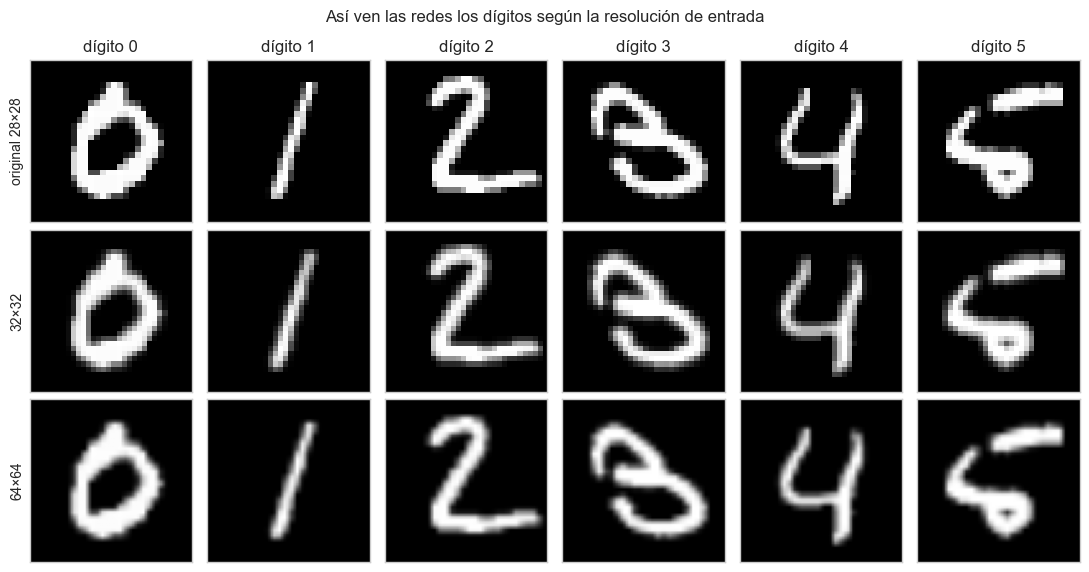

In [6]:
indices = [np.flatnonzero(y_test.numpy() == digit)[0] for digit in CLASSES[:6]]
resolutions = [28, 32, 64]
fig, axes = plt.subplots(len(resolutions), len(indices), figsize=(11, 5.8))
for row, res in enumerate(resolutions):
    for col, index in enumerate(indices):
        ax = axes[row, col]
        image = F.interpolate(x_test[index:index + 1], size=(res, res), mode='bilinear',
                              align_corners=False)[0, 0].numpy()
        ax.imshow(image, cmap='gray')
        if row == 0:
            ax.set_title(f'dígito {int(y_test[index])}')
        if col == 0:
            ax.set_ylabel('original 28×28' if res == 28 else f'{res}×{res}')
        ax.set(xticks=[], yticks=[])
plt.suptitle('Así ven las redes los dígitos según la resolución de entrada')
plt.tight_layout()
plt.show()

## 3. Entrenamiento y selección por validación

Las condiciones son las mismas para todas las configuraciones, de modo que las diferencias se deban a la propuesta:

- mismos datos y preprocesamiento; lote **128**; `torch.manual_seed(SEED)` antes de construir cada modelo y barajado de lotes con un `torch.Generator` fijado a la misma semilla (en MPS la ejecución no es bit a bit reproducible, por eso no se fuerza `torch.use_deterministic_algorithms`);
- **fase A — extracción**: las características de cada extractor se calculan una sola vez para los tres conjuntos en modo `eval()` con lote 256 (ese tiempo se mide aparte, `extract_seconds`); sobre los vectores se entrenan las cabezas con Adam $10^{-3}$ y entropía cruzada, hasta 30 épocas y parada temprana con *patience* 3 restaurando el mejor `state_dict`;
- **fase B — ajuste fino**: se parte de una base ImageNet recién cargada y de los pesos de la cabeza MLP ya entrenada en la fase A; Adam $10^{-4}$ solo sobre los parámetros entrenables, hasta 5 épocas con *patience* 2, siempre con las BatchNormalization congeladas y en modo `eval()`;
- las métricas de entrenamiento se recalculan tras el ajuste en modo `eval()`, es decir, **sin Dropout y con las estadísticas de BatchNorm en inferencia**, para que sean comparables.

El criterio de selección es la exactitud de validación; en caso de empate, menor pérdida de validación y después menor tiempo total. El mejor modelo **completo** (adaptación de entrada + base + cabeza) se conserva como una copia en memoria y se exporta a disco al final de la sección. Las predicciones de test se calculan en el mismo bucle para no tener que repetir la extracción, pero **se guardan aparte y no intervienen en la selección**; solo se muestran en la sección 5.

In [7]:
results = []
test_results = {}
histories = {}
histories_ft = {}
ft_epoch0 = {}
confusion_matrices = {}
trained_mlp_states = {}
best_score = (-np.inf, -np.inf, -np.inf)
best_name = None
best_model = None

run = 0
for spec in EXTRACTORS:
    gc.collect()
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    extractor = build_extractor(spec['backbone'], spec['res'], spec['weights']).to(device)
    sync()
    start = time.perf_counter()
    f_fit = forward_batches(extractor, x_fit, device, PREDICT_BATCH_SIZE)
    f_val = forward_batches(extractor, x_val, device, PREDICT_BATCH_SIZE)
    f_test = forward_batches(extractor, x_test, device, PREDICT_BATCH_SIZE)
    sync()
    extract_seconds = time.perf_counter() - start
    for head_name in ('lineal', 'mlp'):
        run += 1
        name = f"{spec['key']}-{head_name}"
        torch.manual_seed(SEED)
        np.random.seed(SEED)
        head = build_head(f_fit.shape[-1], head_name)
        sync()
        start = time.perf_counter()
        history, epochs_run, restored_epoch = fit(
            head, f_fit, y_fit, f_val, y_val,
            epochs=MAX_EPOCHS_HEAD, patience=PATIENCE_HEAD, lr=LR_HEAD)
        sync()
        train_seconds = time.perf_counter() - start
        model = TransferModel(extractor, head)

        train_accuracy, train_errors, train_matrix, _ = evaluate_predictions(head, f_fit, y_fit, device)
        val_accuracy, val_errors, val_matrix, _ = evaluate_predictions(head, f_val, y_val, device)
        val_loss, _ = loss_and_accuracy(head, f_val, y_val, device)
        results.append({
            'configuration': name,
            'base': spec['backbone'],
            'resolution': spec['res'],
            'weights': 'IMAGENET1K_V1' if spec['weights'] else 'aleatorios',
            'strategy': head_name,
            'seleccionable': True,
            'total_parameters': count_parameters(model),
            'trainable_parameters': count_parameters(model, trainable_only=True),
            'epochs_run': epochs_run,
            'restored_epoch': restored_epoch,
            'train_accuracy': train_accuracy, 'train_errors': train_errors,
            'val_accuracy': val_accuracy, 'val_errors': val_errors, 'val_loss': val_loss,
            'extract_seconds': extract_seconds, 'train_seconds': train_seconds,
            'total_seconds': extract_seconds + train_seconds,
            'accuracy_gap': train_accuracy - val_accuracy,
        })
        histories[name] = history
        confusion_matrices[f'{name}_train'] = train_matrix
        confusion_matrices[f'{name}_val'] = val_matrix
        test_results[name] = evaluate_predictions(head, f_test, y_test, device)
        if head_name == 'mlp' and spec['key'] in KEEP_HEADS:
            trained_mlp_states[spec['key']] = copy.deepcopy(
                {k: v.cpu() for k, v in head.state_dict().items()})
        score = (val_accuracy, -val_loss, -(extract_seconds + train_seconds))
        if score > best_score:
            best_score, best_name = score, name
            best_model = copy.deepcopy(model).cpu()
        print(
            f'[{run:02d}/{len(EXTRACTORS) * 2}] {name:<31} train={train_accuracy:.4%} ({train_errors:>4} err) '
            f'val={val_accuracy:.4%} ({val_errors:>3} err) épocas={epochs_run:>2} '
            f'extraer={extract_seconds:6.1f}s cabeza={train_seconds:5.1f}s'
        )
        del head, model
    del extractor, f_fit, f_val, f_test
    gc.collect()
    if device.type == 'mps':
        torch.mps.empty_cache()

[01/18] vgg16-32-congelada-lineal       train=94.5148% (2962 err) val=93.1333% (412 err) épocas=30 extraer=  18.4s cabeza= 19.2s


[02/18] vgg16-32-congelada-mlp          train=96.0741% (2120 err) val=94.2500% (345 err) épocas=15 extraer=  18.4s cabeza= 11.3s


[03/18] vgg19-32-congelada-lineal       train=93.7722% (3363 err) val=92.7167% (437 err) épocas=30 extraer=  21.6s cabeza= 18.9s


[04/18] vgg19-32-congelada-mlp          train=95.6296% (2360 err) val=94.0333% (358 err) épocas=19 extraer=  21.6s cabeza= 16.4s


[05/18] resnet50-32-congelada-lineal    train=98.3963% ( 866 err) val=96.8333% (190 err) épocas=23 extraer=  38.0s cabeza= 15.1s


[06/18] resnet50-32-congelada-mlp       train=97.7537% (1213 err) val=96.4667% (212 err) épocas=18 extraer=  38.0s cabeza= 38.2s


... (9 outputs left out)

[15/18] alexnet-64-congelada-lineal     train=94.7815% (2818 err) val=94.0667% (356 err) épocas=16 extraer=   5.2s cabeza=  9.4s


[16/18] alexnet-64-congelada-mlp        train=97.2630% (1478 err) val=95.4167% (275 err) épocas=16 extraer=   5.2s cabeza= 12.3s


[17/18] resnet50-32-aleatoria-lineal    train=91.0500% (4833 err) val=90.0500% (597 err) épocas=11 extraer=  38.4s cabeza=  7.8s


[18/18] resnet50-32-aleatoria-mlp       train=11.3741% (47858 err) val=10.0000% (5400 err) épocas= 4 extraer=  38.4s cabeza=  9.4s


### 3.1 Ajuste fino (*fine-tuning*)

Cada configuración de ajuste fino parte de una base **recién cargada con pesos ImageNet** y de los **pesos de la cabeza MLP ya entrenada** en la fase A sobre el mismo extractor: la cabeza ya clasifica razonablemente, así que los primeros gradientes que llegan a la base descongelada son pequeños y coherentes en lugar de destruir los filtros preentrenados.

- *Parcial*: solo entrena el último bloque convolucional (`features[24:]` —el bloque 5— en VGG16, `layer4` en ResNet50, `features.denseblock4` en DenseNet121).
- *Total*: entrena toda la base.

En ambos casos las capas **BatchNormalization conservan `requires_grad = False` y se mantienen en modo `eval()`** (se reaplica tras cada `model.train()`), como recomienda la guía de Keras para *fine-tuning*: si las estadísticas de BN se rehicieran con lotes de dígitos, se desajustaría el resto de la red. La cabeza (con su Dropout) sí entrena siempre. La tasa de aprendizaje baja a $10^{-4}$ y solo se permiten 5 épocas con *patience* 2. En las curvas de aprendizaje, la **época 0** marca el punto de partida: el rendimiento de la cabeza de la fase A.

In [8]:
for i, spec in enumerate(FT_CONFIGS, start=1):
    gc.collect()
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    extractor = build_extractor(spec['backbone'], spec['res'], 'imagenet')
    unfreeze_backbone(extractor, spec['backbone'], spec['corte'])
    head = build_head(FEATURE_DIMS[spec['backbone']], 'mlp')
    head.load_state_dict(trained_mlp_states[spec['fuente']])
    reference_row = next(row for row in results if row['configuration'] == f"{spec['fuente']}-mlp")
    ft_epoch0[spec['name']] = {'val_loss': reference_row['val_loss'],
                               'val_accuracy': reference_row['val_accuracy']}
    model = TransferModel(extractor, head)
    base_trainable = count_parameters(extractor, trainable_only=True)

    sync()
    start = time.perf_counter()
    history, epochs_run, restored_epoch = fit(
        model, x_fit, y_fit, x_val, y_val,
        epochs=MAX_EPOCHS_FT, patience=PATIENCE_FT, lr=LR_FT)
    sync()
    train_seconds = time.perf_counter() - start

    train_accuracy, train_errors, train_matrix, _ = evaluate_predictions(model, x_fit, y_fit, device)
    val_accuracy, val_errors, val_matrix, _ = evaluate_predictions(model, x_val, y_val, device)
    val_loss, _ = loss_and_accuracy(model, x_val, y_val, device)
    results.append({
        'configuration': spec['name'],
        'base': spec['backbone'],
        'resolution': spec['res'],
        'weights': 'IMAGENET1K_V1',
        'strategy': spec['strategy'],
        'seleccionable': True,
        'total_parameters': count_parameters(model),
        'trainable_parameters': count_parameters(model, trainable_only=True),
        'epochs_run': epochs_run,
        'restored_epoch': restored_epoch,
        'train_accuracy': train_accuracy, 'train_errors': train_errors,
        'val_accuracy': val_accuracy, 'val_errors': val_errors, 'val_loss': val_loss,
        'extract_seconds': np.nan, 'train_seconds': train_seconds,
        'total_seconds': train_seconds,
        'accuracy_gap': train_accuracy - val_accuracy,
    })
    histories_ft[spec['name']] = history
    confusion_matrices[f"{spec['name']}_train"] = train_matrix
    confusion_matrices[f"{spec['name']}_val"] = val_matrix
    test_results[spec['name']] = evaluate_predictions(model, x_test, y_test, device)
    score = (val_accuracy, -val_loss, -train_seconds)
    if score > best_score:
        best_score, best_name = score, spec['name']
        best_model = copy.deepcopy(model).cpu()
    print(
        f'[{i:02d}/{len(FT_CONFIGS)}] {spec["name"]:<31} train={train_accuracy:.4%} ({train_errors:>4} err) '
        f'val={val_accuracy:.4%} ({val_errors:>3} err) épocas={epochs_run:>2} '
        f'(época 0: {ft_epoch0[spec["name"]]["val_accuracy"]:.4%}) tiempo={train_seconds:6.1f}s '
        f'base_entrenable={base_trainable:,}'
    )
    del model, head, extractor
    gc.collect()
    if device.type == 'mps':
        torch.mps.empty_cache()

[01/7] vgg16-32-ft-parcial             train=99.4352% ( 305 err) val=98.6833% ( 79 err) épocas= 5 (época 0: 94.2500%) tiempo= 122.4s base_entrenable=7,079,424


[02/7] vgg16-32-ft-total               train=99.5593% ( 238 err) val=98.9833% ( 61 err) épocas= 4 (época 0: 94.2500%) tiempo= 271.2s base_entrenable=14,714,688


[03/7] resnet50-32-ft-parcial          train=99.0889% ( 492 err) val=98.3833% ( 97 err) épocas= 5 (época 0: 96.4667%) tiempo= 333.5s base_entrenable=14,942,208


[04/7] resnet50-32-ft-total            train=98.9130% ( 587 err) val=98.5500% ( 87 err) épocas= 3 (época 0: 96.4667%) tiempo= 295.7s base_entrenable=23,454,912


[05/7] densenet121-32-ft-parcial       train=98.3111% ( 912 err) val=96.8500% (189 err) épocas= 5 (época 0: 96.2667%) tiempo= 109.8s base_entrenable=2,129,920


[06/7] densenet121-32-ft-total         train=99.6870% ( 169 err) val=99.1167% ( 53 err) épocas= 5 (época 0: 96.2667%) tiempo= 231.1s base_entrenable=6,870,208


[07/7] densenet121-64-ft-total         train=99.6796% ( 173 err) val=99.2333% ( 46 err) épocas= 5 (época 0: 97.0333%) tiempo= 543.5s base_entrenable=6,870,208


### 3.2 Referencia: la CNN de la práctica 3

La mejor red de la práctica 3 (`vgg-bn-dropout`, 468 394 parámetros) se entrenó **desde cero** sobre exactamente la misma partición y obtuvo un 98,967 % y 62 errores en validación. Como está guardada en formato Keras y en este cuaderno no se usa TensorFlow, sus métricas y matrices de confusión se toman de `resultados_configuraciones.csv` y `matrices_confusion.npz` de la práctica 3, y se comprueba que sus filas suman exactamente los ejemplos de esta partición (600 por clase en validación y los recuentos de cada clase del ajuste). Se añade a la tabla como `cnn-p3-desde-cero`, marcada como **no seleccionable**: el ganador de esta práctica debe ser un modelo obtenido por transferencia.

In [9]:
reference_name = 'cnn-p3-desde-cero'
p3_table = pd.read_csv(PRACTICA3_DIR / 'resultados_configuraciones.csv')
p3_row = p3_table.loc[p3_table['configuration'] == 'vgg-bn-dropout'].iloc[0]
with np.load(PRACTICA3_DIR / 'matrices_confusion.npz') as p3_matrices:
    ref_train_matrix = p3_matrices['vgg-bn-dropout_train'].copy()
    ref_val_matrix = p3_matrices['vgg-bn-dropout_val'].copy()
    ref_test_matrix = p3_matrices['vgg-bn-dropout_test'].copy()
if not (ref_val_matrix.sum(axis=1) == np.bincount(y_val.numpy(), minlength=10)).all():
    raise RuntimeError('La validación de la práctica 3 no coincide con esta partición')
if not (ref_train_matrix.sum(axis=1) == np.bincount(y_fit.numpy(), minlength=10)).all():
    raise RuntimeError('El ajuste de la práctica 3 no coincide con esta partición')
train_accuracy = float(np.trace(ref_train_matrix) / ref_train_matrix.sum())
train_errors = int(ref_train_matrix.sum() - np.trace(ref_train_matrix))
val_accuracy = float(np.trace(ref_val_matrix) / ref_val_matrix.sum())
val_errors = int(ref_val_matrix.sum() - np.trace(ref_val_matrix))
if val_errors != 62 or not np.isclose(val_accuracy, p3_row['val_accuracy']):
    raise RuntimeError('La referencia de la práctica 3 no reproduce sus 62 errores de validación')
results.append({
    'configuration': reference_name,
    'base': 'cnn propia',
    'resolution': 28,
    'weights': '—',
    'strategy': 'desde cero',
    'seleccionable': False,
    'total_parameters': int(p3_row['parameters']),
    'trainable_parameters': int(p3_row['parameters']),
    'epochs_run': int(p3_row['epochs_run']),
    'restored_epoch': int(p3_row['restored_epoch']),
    'train_accuracy': train_accuracy, 'train_errors': train_errors,
    'val_accuracy': val_accuracy, 'val_errors': val_errors,
    'val_loss': float(p3_row['val_loss']),
    'extract_seconds': np.nan, 'train_seconds': float(p3_row['train_seconds']),
    'total_seconds': float(p3_row['train_seconds']),
    'accuracy_gap': train_accuracy - val_accuracy,
})
confusion_matrices[f'{reference_name}_train'] = ref_train_matrix
confusion_matrices[f'{reference_name}_val'] = ref_val_matrix
test_results[reference_name] = (
    float(np.trace(ref_test_matrix) / ref_test_matrix.sum()),
    int(ref_test_matrix.sum() - np.trace(ref_test_matrix)), ref_test_matrix, None)
print(
    f'[ref] {reference_name:<29} train={train_accuracy:.4%} ({train_errors:>4} err) '
    f'val={val_accuracy:.4%} ({val_errors:>3} err)  ← reproduce los 62 errores de la práctica 3'
)

results_df = pd.DataFrame(results).sort_values(
    ['val_accuracy', 'val_loss', 'total_seconds'], ascending=[False, True, True]
).reset_index(drop=True)
eligible = results_df[results_df['seleccionable']]
assert best_name == eligible.iloc[0]['configuration']

model_path = BASE_DIR / 'mejor_modelo_transfer_mnist.pt2'
example_batch = x_val[:1]
try:
    exported_program = torch.export.export(
        copy.deepcopy(best_model).cpu().eval(), (example_batch,),
        dynamic_shapes=({0: torch.export.Dim('batch', min=1)},))
    torch.export.save(exported_program, str(model_path))
    export_format = 'torch.export (.pt2)'
except Exception as error:
    model_path = BASE_DIR / 'mejor_modelo_transfer_mnist.pt'
    torch.jit.trace(copy.deepcopy(best_model).cpu().eval(), example_batch).save(str(model_path))
    export_format = f'torch.jit.trace (.pt) — torch.export falló: {type(error).__name__}'
print(f'\nSeleccionado por validación: {best_name}  →  exportado a {model_path.name} ({export_format})')

[ref] cnn-p3-desde-cero             train=99.3889% ( 330 err) val=98.9667% ( 62 err)  ← reproduce los 62 errores de la práctica 3


/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(



Seleccionado por validación: densenet121-64-ft-total  →  exportado a mejor_modelo_transfer_mnist.pt (torch.jit.trace (.pt) — torch.export falló: UserError)


## 4. Comparación numérica y gráfica

La tabla está ordenada de mejor a peor exactitud de validación. `extract_seconds` es el tiempo de calcular las características de los tres conjuntos con el extractor congelado (lo comparten las dos cabezas de ese extractor); `train_seconds` es el ajuste de la cabeza o el *fine-tuning*; `total_seconds`, la suma. Para los ajustes finos no hay extracción separable, así que `extract_seconds` aparece como `—`. `accuracy_gap` = exactitud de entrenamiento − exactitud de validación: una brecha grande indica sobreajuste. La referencia `cnn-p3-desde-cero` aparece marcada con `seleccionable = False`.

,configuration,base,resolution,weights,strategy,seleccionable,total_parameters,trainable_parameters,epochs_run,restored_epoch,train_accuracy,train_errors,val_accuracy,val_errors,val_loss,extract_seconds,train_seconds,total_seconds,accuracy_gap
0,densenet121-64-ft-total,densenet121,64,IMAGENET1K_V1,ft-total,True,"7,218,826","7,135,178",5,3,99.680%,173,99.233%,46,0.0297,—,544,544,0.446%
1,densenet121-32-ft-total,densenet121,32,IMAGENET1K_V1,ft-total,True,"7,218,826","7,135,178",5,4,99.687%,169,99.117%,53,0.0411,—,231,231,0.570%
2,vgg16-32-ft-total,vgg16,32,IMAGENET1K_V1,ft-total,True,"14,848,586","14,848,586",4,2,99.559%,238,98.983%,61,0.0409,—,271,271,0.576%
3,cnn-p3-desde-cero,cnn propia,28,—,desde cero,False,"468,394","468,394",10,7,99.389%,330,98.967%,62,0.0381,—,363,363,0.422%
4,vgg16-32-ft-parcial,vgg16,32,IMAGENET1K_V1,ft-parcial,True,"14,848,586","7,213,322",5,4,99.435%,305,98.683%,79,0.0562,—,122,122,0.752%
5,resnet50-32-ft-total,resnet50,32,IMAGENET1K_V1,ft-total,True,"24,035,146","23,982,026",3,1,98.913%,587,98.550%,87,0.0546,—,296,296,0.363%
6,resnet50-32-ft-parcial,resnet50,32,IMAGENET1K_V1,ft-parcial,True,"24,035,146","15,469,322",5,3,99.089%,492,98.383%,97,0.0588,—,334,334,0.706%
7,densenet121-64-congelada-lineal,densenet121,64,IMAGENET1K_V1,lineal,True,"6,964,106","10,250",25,22,98.407%,860,97.217%,167,0.0918,44,16,60,1.191%
8,densenet121-64-congelada-mlp,densenet121,64,IMAGENET1K_V1,mlp,True,"7,218,826","264,970",12,9,98.113%,1019,97.033%,178,0.0981,44,17,62,1.080%
9,densenet121-32-ft-parcial,densenet121,32,IMAGENET1K_V1,ft-parcial,True,"7,218,826","2,394,890",5,3,98.311%,912,96.850%,189,0.1115,—,110,110,1.461%


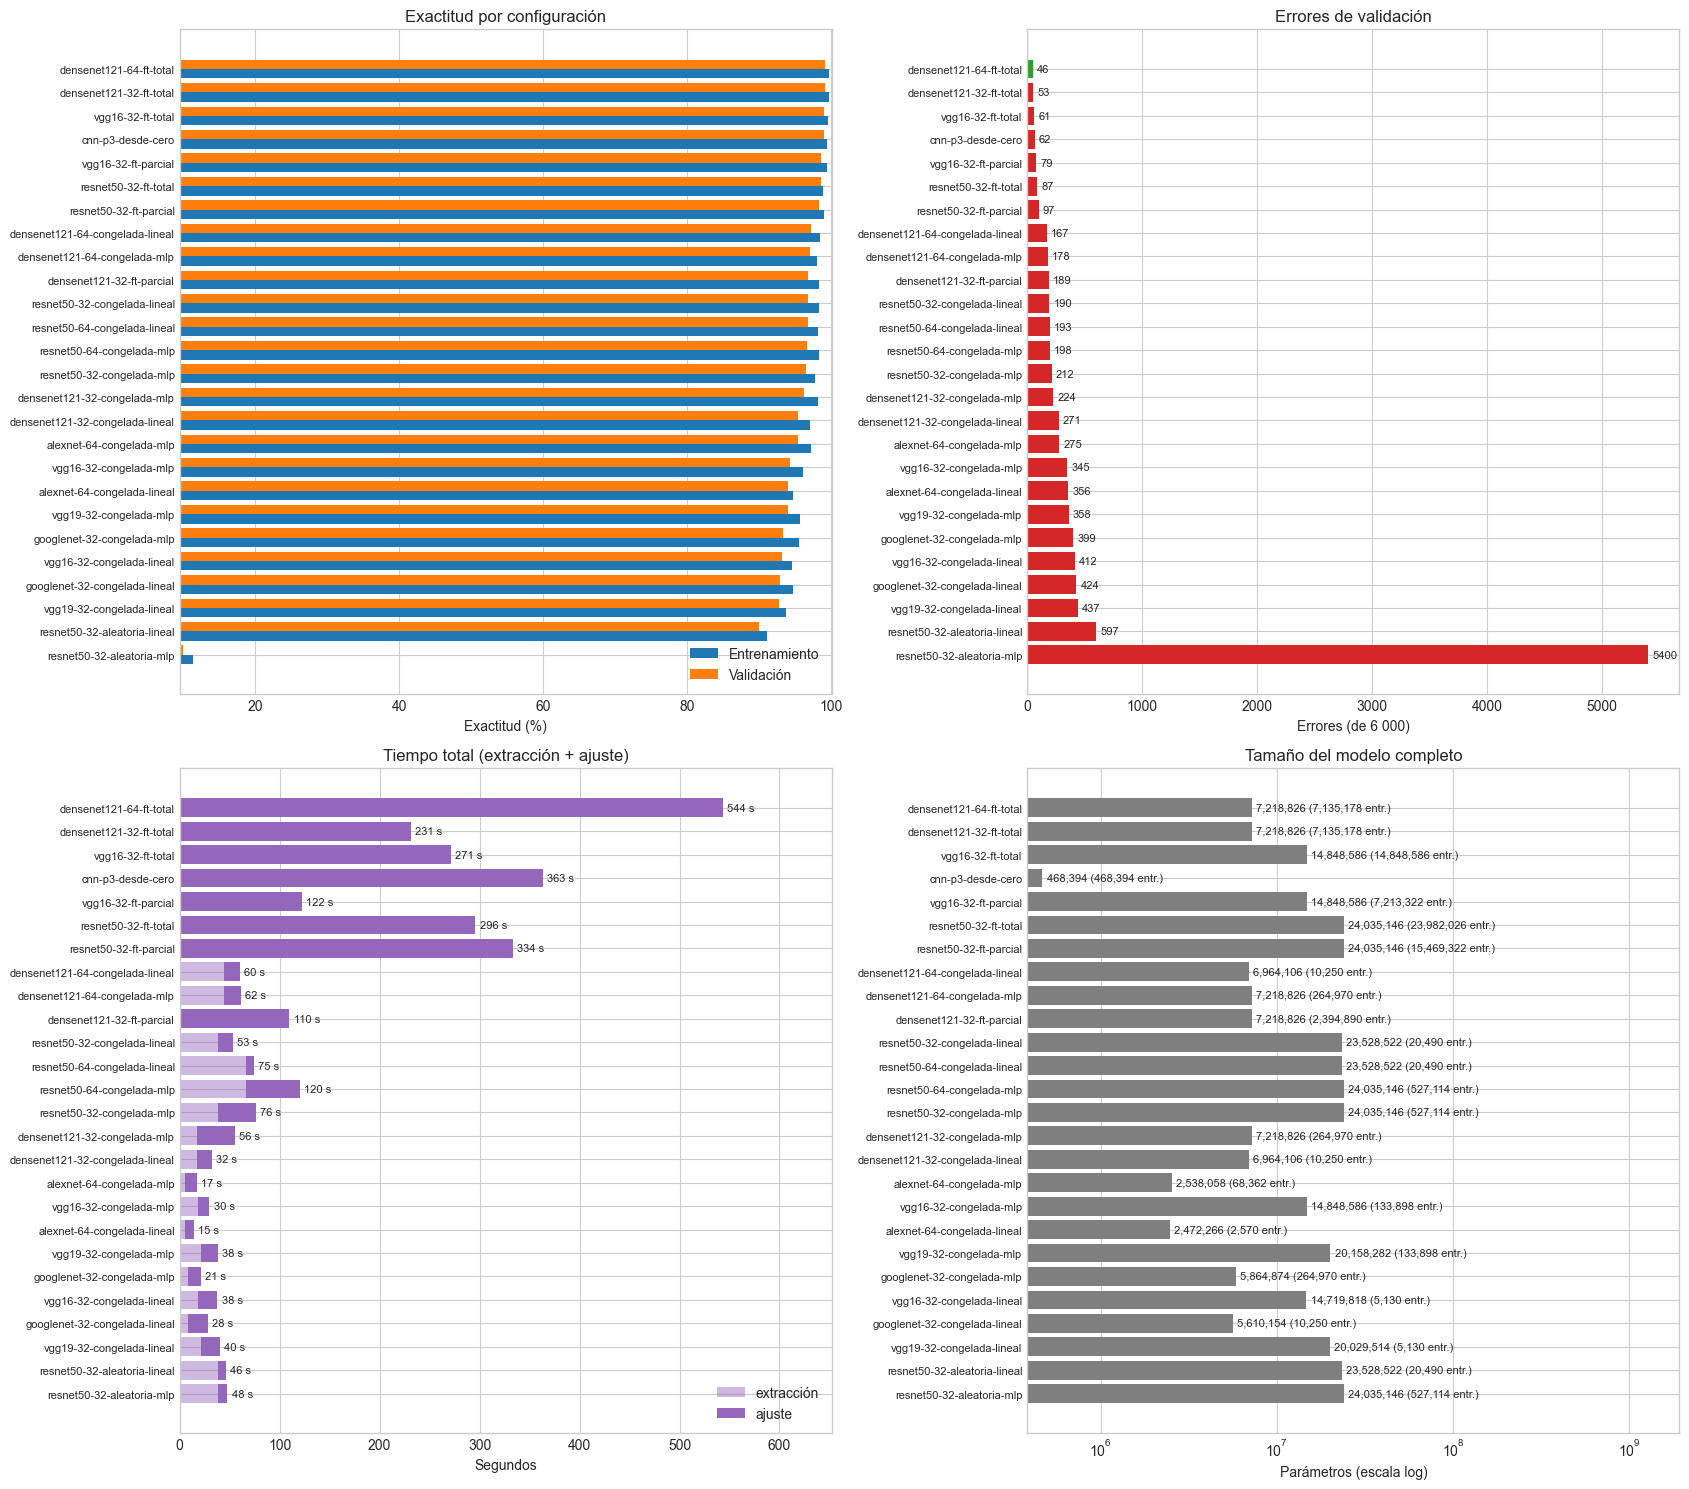

In [10]:
display(results_df.style.format({
    'total_parameters': '{:,}', 'trainable_parameters': '{:,}',
    'train_accuracy': '{:.3%}', 'val_accuracy': '{:.3%}', 'val_loss': '{:.4f}',
    'extract_seconds': '{:.0f}', 'train_seconds': '{:.0f}', 'total_seconds': '{:.0f}',
    'accuracy_gap': '{:.3%}',
}, na_rep='—').background_gradient(subset=['val_accuracy'], cmap='Greens'))

plot_df = results_df.sort_values('val_accuracy')
positions = np.arange(len(plot_df))
is_best = plot_df['configuration'].eq(best_name).to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
ax = axes[0, 0]
ax.barh(positions - 0.2, plot_df['train_accuracy'] * 100, height=0.4, label='Entrenamiento')
ax.barh(positions + 0.2, plot_df['val_accuracy'] * 100, height=0.4, label='Validación')
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Exactitud (%)',
       title='Exactitud por configuración',
       xlim=(np.floor(plot_df[['train_accuracy', 'val_accuracy']].min().min() * 100) - 0.5, 100.1))
ax.tick_params(axis='y', labelsize=8)
ax.legend(loc='lower right')
ax = axes[0, 1]
bars = ax.barh(positions, plot_df['val_errors'], color=np.where(is_best, 'tab:green', 'tab:red'))
ax.bar_label(bars, padding=3, fontsize=8)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Errores (de 6 000)',
       title='Errores de validación')
ax.tick_params(axis='y', labelsize=8)
ax = axes[1, 0]
extract = plot_df['extract_seconds'].fillna(0)
bars_extract = ax.barh(positions, extract, color='tab:purple', alpha=0.45, label='extracción')
bars_train = ax.barh(positions, plot_df['train_seconds'], left=extract, color='tab:purple', label='ajuste')
ax.bar_label(bars_train, labels=[f'{t:.0f} s' for t in extract + plot_df['train_seconds']], padding=3, fontsize=8)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Segundos',
       title='Tiempo total (extracción + ajuste)')
ax.tick_params(axis='y', labelsize=8)
ax.set_xlim(0, (extract + plot_df['train_seconds']).max() * 1.2)
ax.legend(loc='lower right')
ax = axes[1, 1]
bars = ax.barh(positions, plot_df['total_parameters'], color='tab:gray')
ax.bar_label(bars, labels=[
    f'{t:,} ({tr:,} entr.)' for t, tr in zip(plot_df['total_parameters'], plot_df['trainable_parameters'])
], padding=3, fontsize=8)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Parámetros (escala log)',
       title='Tamaño del modelo completo', xscale='log')
ax.tick_params(axis='y', labelsize=8)
ax.set_xlim(right=plot_df['total_parameters'].max() * 80)
plt.tight_layout()
plt.show()

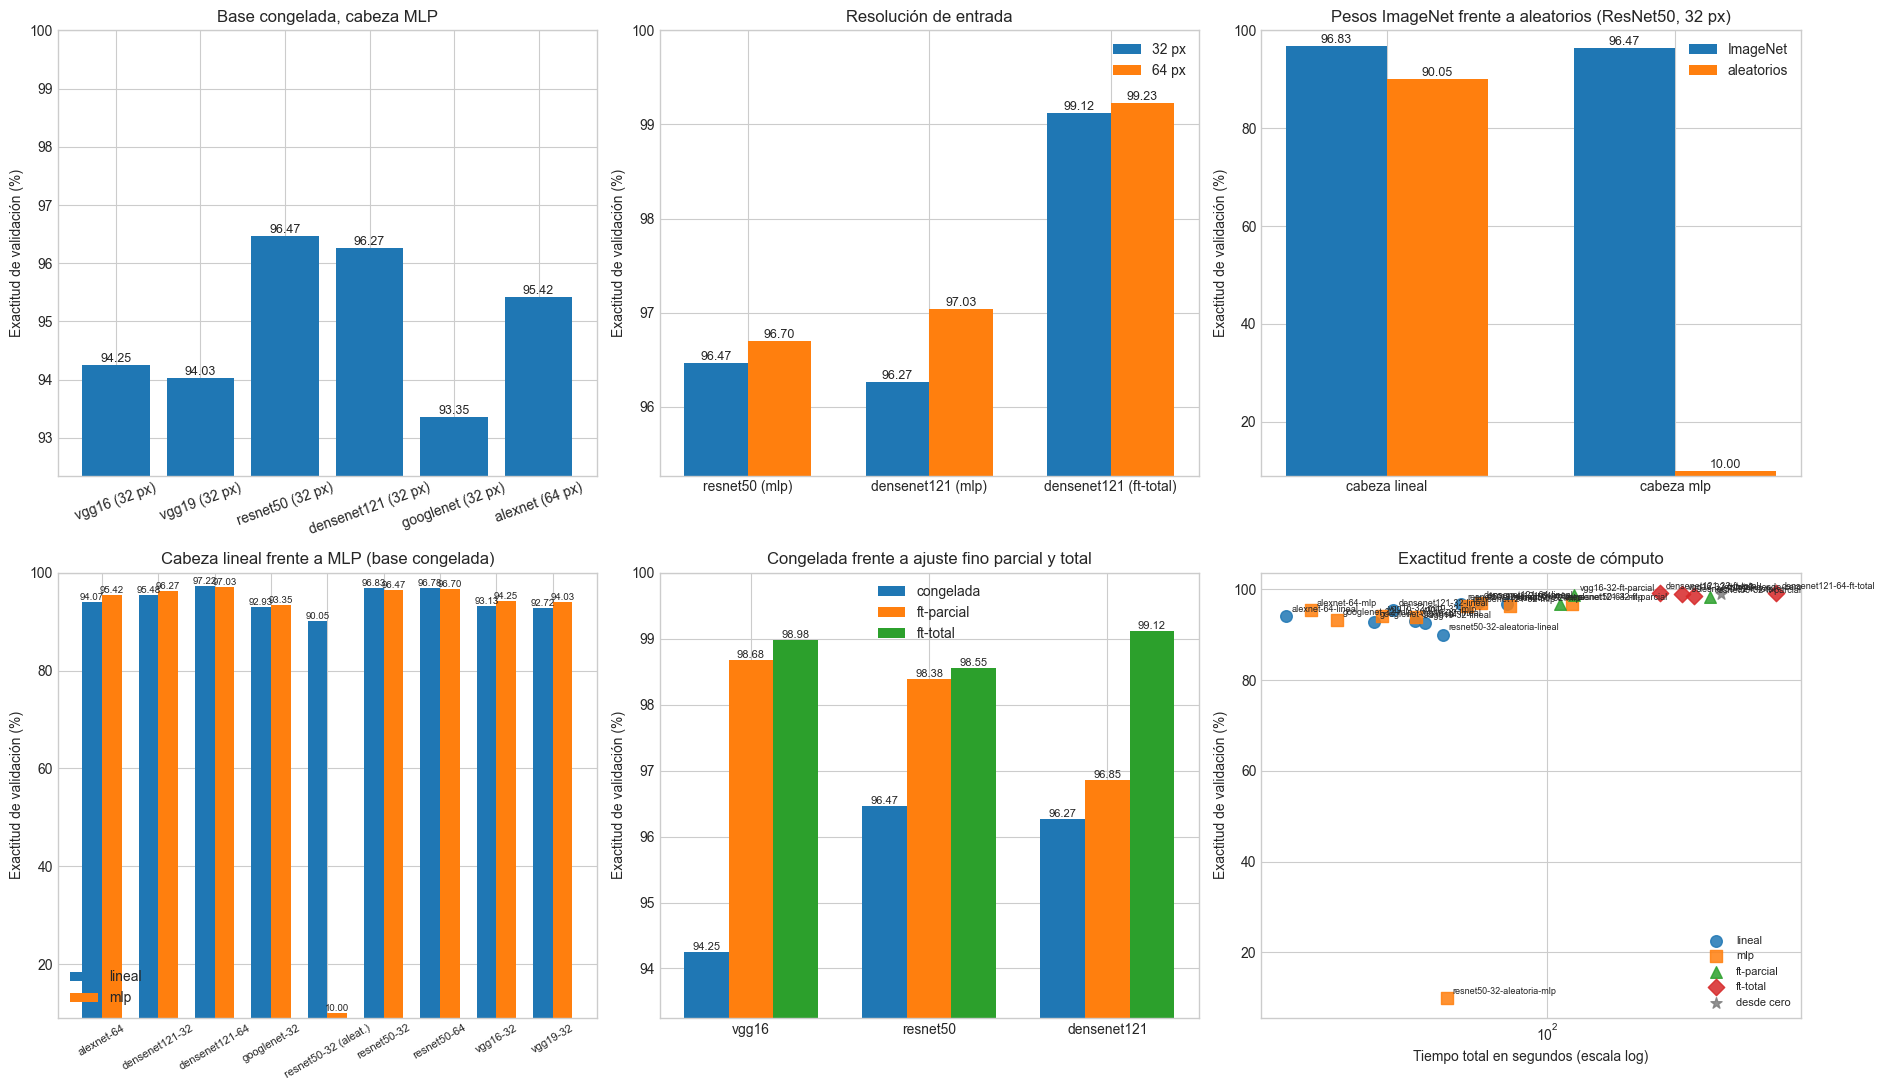

In [11]:
by_name = results_df.set_index('configuration')


def acc(name):
    return by_name.loc[name]['val_accuracy'] * 100 if name in by_name.index else np.nan


fig, axes = plt.subplots(2, 3, figsize=(19, 11))

ax = axes[0, 0]
group = [n for n in ['vgg16-32-congelada-mlp', 'vgg19-32-congelada-mlp',
                     'resnet50-32-congelada-mlp', 'densenet121-32-congelada-mlp',
                     'googlenet-32-congelada-mlp', 'alexnet-64-congelada-mlp']
         if n in by_name.index]
labels = [n.replace('-congelada-mlp', '').replace('-32', ' (32 px)').replace('-64', ' (64 px)') for n in group]
bars = ax.bar(labels, [acc(n) for n in group], color='tab:blue')
ax.bar_label(bars, fmt='%.2f', fontsize=9)
ax.set(ylabel='Exactitud de validación (%)', title='Base congelada, cabeza MLP')
ax.tick_params(axis='x', rotation=20)
ax.set_ylim(min(acc(n) for n in group) - 1, 100)

ax = axes[0, 1]
width = 0.35
groups = [('resnet50 (mlp)', 'resnet50-32-congelada-mlp', 'resnet50-64-congelada-mlp'),
          ('densenet121 (mlp)', 'densenet121-32-congelada-mlp', 'densenet121-64-congelada-mlp'),
          ('densenet121 (ft-total)', 'densenet121-32-ft-total', 'densenet121-64-ft-total')]
groups = [g for g in groups if g[1] in by_name.index and g[2] in by_name.index]
xpos = np.arange(len(groups))
for k, res in enumerate((32, 64)):
    vals = [acc(g[k + 1]) for g in groups]
    bars = ax.bar(xpos + (k - 0.5) * width, vals, width, label=f'{res} px')
    ax.bar_label(bars, fmt='%.2f', fontsize=9)
ax.set(xticks=xpos, xticklabels=[g[0] for g in groups],
       ylabel='Exactitud de validación (%)', title='Resolución de entrada')
ax.legend()
if groups:
    low = np.nanmin([acc(g[1]) for g in groups] + [acc(g[2]) for g in groups])
    ax.set_ylim(low - 1, 100)

ax = axes[0, 2]
pairs = [('lineal', 'resnet50-32-congelada-lineal', 'resnet50-32-aleatoria-lineal'),
         ('mlp', 'resnet50-32-congelada-mlp', 'resnet50-32-aleatoria-mlp')]
xpos = np.arange(len(pairs))
for k, key in enumerate(('imagenet', 'aleatorios')):
    vals = [acc(p[k + 1]) for p in pairs]
    bars = ax.bar(xpos + (k - 0.5) * width, vals, width,
                  label='ImageNet' if key == 'imagenet' else 'aleatorios')
    ax.bar_label(bars, fmt='%.2f', fontsize=9)
ax.set(xticks=xpos, xticklabels=[f'cabeza {p[0]}' for p in pairs],
       ylabel='Exactitud de validación (%)', title='Pesos ImageNet frente a aleatorios (ResNet50, 32 px)')
ax.legend()
low = np.nanmin([acc(p[1]) for p in pairs] + [acc(p[2]) for p in pairs])
ax.set_ylim(low - 1, 100)

ax = axes[1, 0]
extractor_keys = sorted({n.rsplit('-', 1)[0] for n in by_name.index if n.endswith(('-lineal', '-mlp'))})
xpos = np.arange(len(extractor_keys))
for k, head_name in enumerate(('lineal', 'mlp')):
    vals = [acc(f'{key}-{head_name}') for key in extractor_keys]
    bars = ax.bar(xpos + (k - 0.5) * width, vals, width, label=head_name)
    ax.bar_label(bars, fmt='%.2f', fontsize=7)
ax.set(xticks=xpos,
       xticklabels=[k.replace('-congelada', '').replace('-aleatoria', ' (aleat.)') for k in extractor_keys],
       ylabel='Exactitud de validación (%)', title='Cabeza lineal frente a MLP (base congelada)')
ax.tick_params(axis='x', rotation=30, labelsize=8)
ax.legend()
low = np.nanmin([acc(f'{key}-{h}') for key in extractor_keys for h in ('lineal', 'mlp')])
ax.set_ylim(low - 1, 100)

ax = axes[1, 1]
groups = [('vgg16', ['vgg16-32-congelada-mlp', 'vgg16-32-ft-parcial', 'vgg16-32-ft-total']),
          ('resnet50', ['resnet50-32-congelada-mlp', 'resnet50-32-ft-parcial', 'resnet50-32-ft-total']),
          ('densenet121', ['densenet121-32-congelada-mlp', 'densenet121-32-ft-parcial', 'densenet121-32-ft-total'])]
groups = [(g, names) for g, names in groups if any(n in by_name.index for n in names)]
labels = ['congelada', 'ft-parcial', 'ft-total']
xpos = np.arange(len(groups))
width3 = 0.25
for k, label in enumerate(labels):
    vals = [acc(names[k]) for _, names in groups]
    bars = ax.bar(xpos + (k - 1) * width3, vals, width3, label=label)
    ax.bar_label(bars, fmt='%.2f', fontsize=8)
ax.set(xticks=xpos, xticklabels=[g for g, _ in groups],
       ylabel='Exactitud de validación (%)', title='Congelada frente a ajuste fino parcial y total')
ax.legend()
low = np.nanmin([acc(n) for _, names in groups for n in names])
ax.set_ylim(low - 1, 100)

ax = axes[1, 2]
strategy_style = {'lineal': ('o', 'tab:blue'), 'mlp': ('s', 'tab:orange'),
                  'ft-parcial': ('^', 'tab:green'), 'ft-total': ('D', 'tab:red'),
                  'desde cero': ('*', 'tab:gray')}
for strategy, (marker, color) in strategy_style.items():
    sub = results_df[results_df['strategy'] == strategy]
    ax.scatter(sub['total_seconds'], sub['val_accuracy'] * 100, marker=marker,
               color=color, s=70, label=strategy, alpha=0.85)
    for _, row in sub.iterrows():
        ax.annotate(row['configuration'].replace('-congelada', ''),
                    (row['total_seconds'], row['val_accuracy'] * 100),
                    fontsize=6.5, xytext=(4, 3), textcoords='offset points')
ax.set(xscale='log', xlabel='Tiempo total en segundos (escala log)',
       ylabel='Exactitud de validación (%)', title='Exactitud frente a coste de cómputo')
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.show()

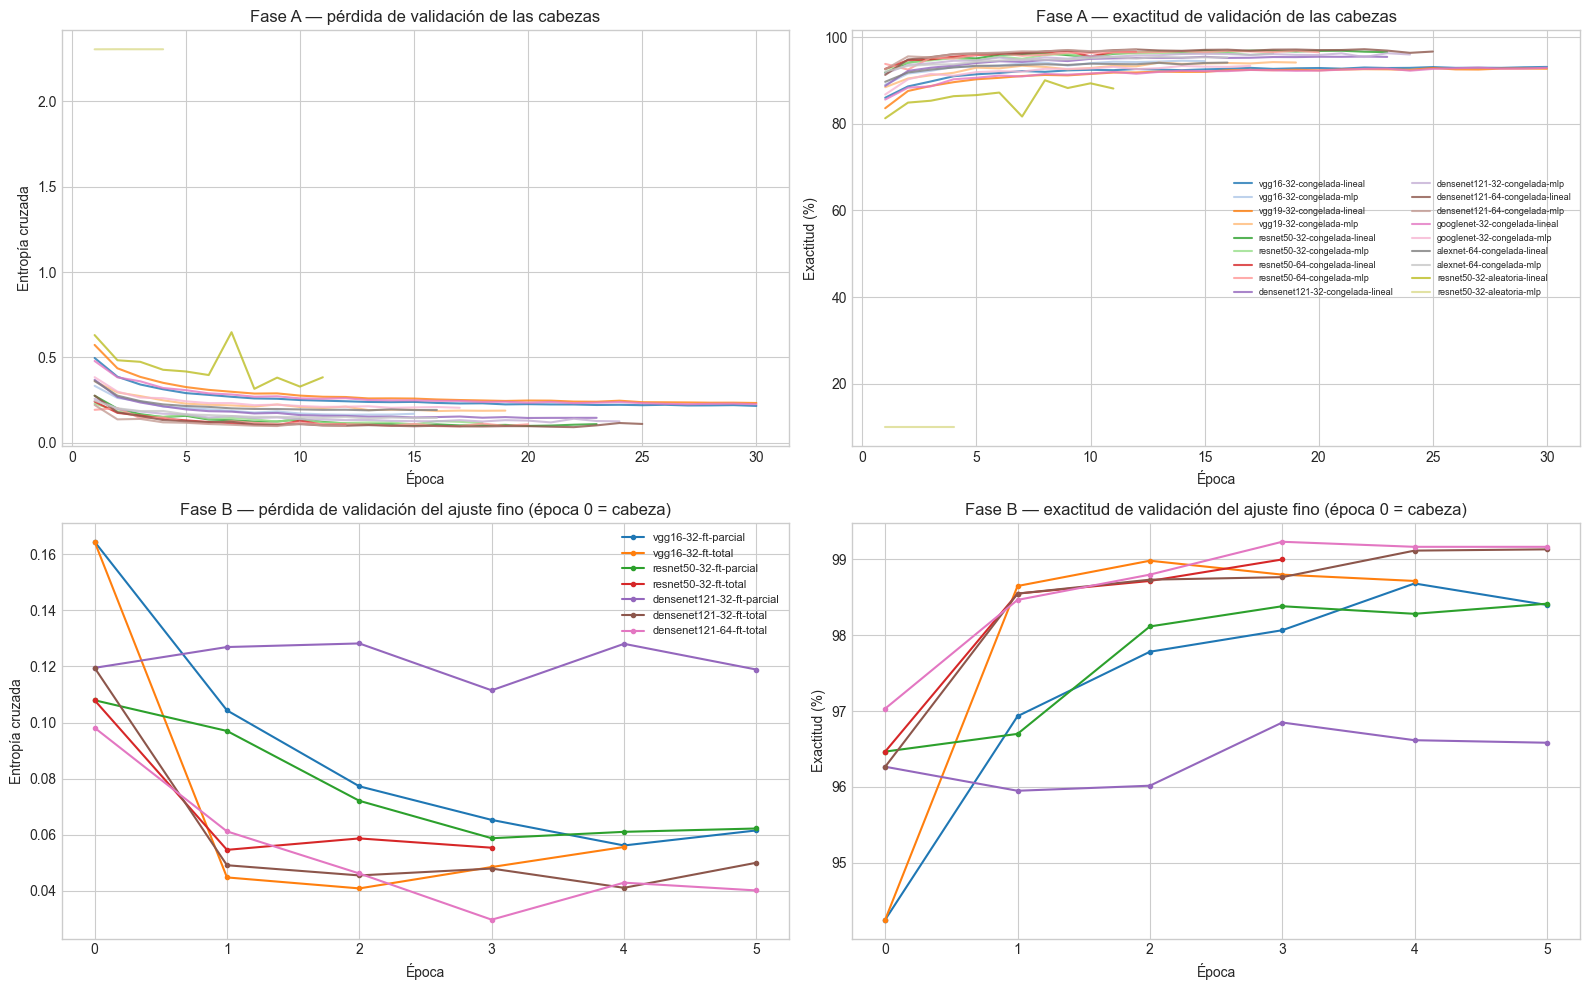

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
cmap_a = plt.get_cmap('tab20')
for i, (name, history) in enumerate(histories.items()):
    epochs = np.arange(1, len(history['loss']) + 1)
    axes[0, 0].plot(epochs, history['val_loss'], color=cmap_a(i), alpha=0.8)
    axes[0, 1].plot(epochs, np.array(history['val_accuracy']) * 100, color=cmap_a(i), alpha=0.8, label=name)
axes[0, 0].set(xlabel='Época', ylabel='Entropía cruzada', title='Fase A — pérdida de validación de las cabezas')
axes[0, 1].set(xlabel='Época', ylabel='Exactitud (%)', title='Fase A — exactitud de validación de las cabezas')
axes[0, 1].legend(fontsize=6.5, ncol=2, loc='center right')

cmap_b = plt.get_cmap('tab10')
for i, (name, history) in enumerate(histories_ft.items()):
    start = ft_epoch0[name]
    epochs = np.arange(0, len(history['loss']) + 1)
    axes[1, 0].plot(epochs, [start['val_loss']] + history['val_loss'], color=cmap_b(i), marker='.', label=name)
    axes[1, 1].plot(epochs, [start['val_accuracy'] * 100] + [a * 100 for a in history['val_accuracy']],
                    color=cmap_b(i), marker='.', label=name)
axes[1, 0].set(xlabel='Época', ylabel='Entropía cruzada',
               title='Fase B — pérdida de validación del ajuste fino (época 0 = cabeza)')
axes[1, 1].set(xlabel='Época', ylabel='Exactitud (%)',
               title='Fase B — exactitud de validación del ajuste fino (época 0 = cabeza)')
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Matrices de confusión

Convención: filas = clase real, columnas = predicción. Cada celda muestra el recuento absoluto; el color se normaliza por fila. Se muestran las matrices de validación de todas las configuraciones y, después, las de entrenamiento y validación de cada una en el fichero `matrices_confusion.npz`.

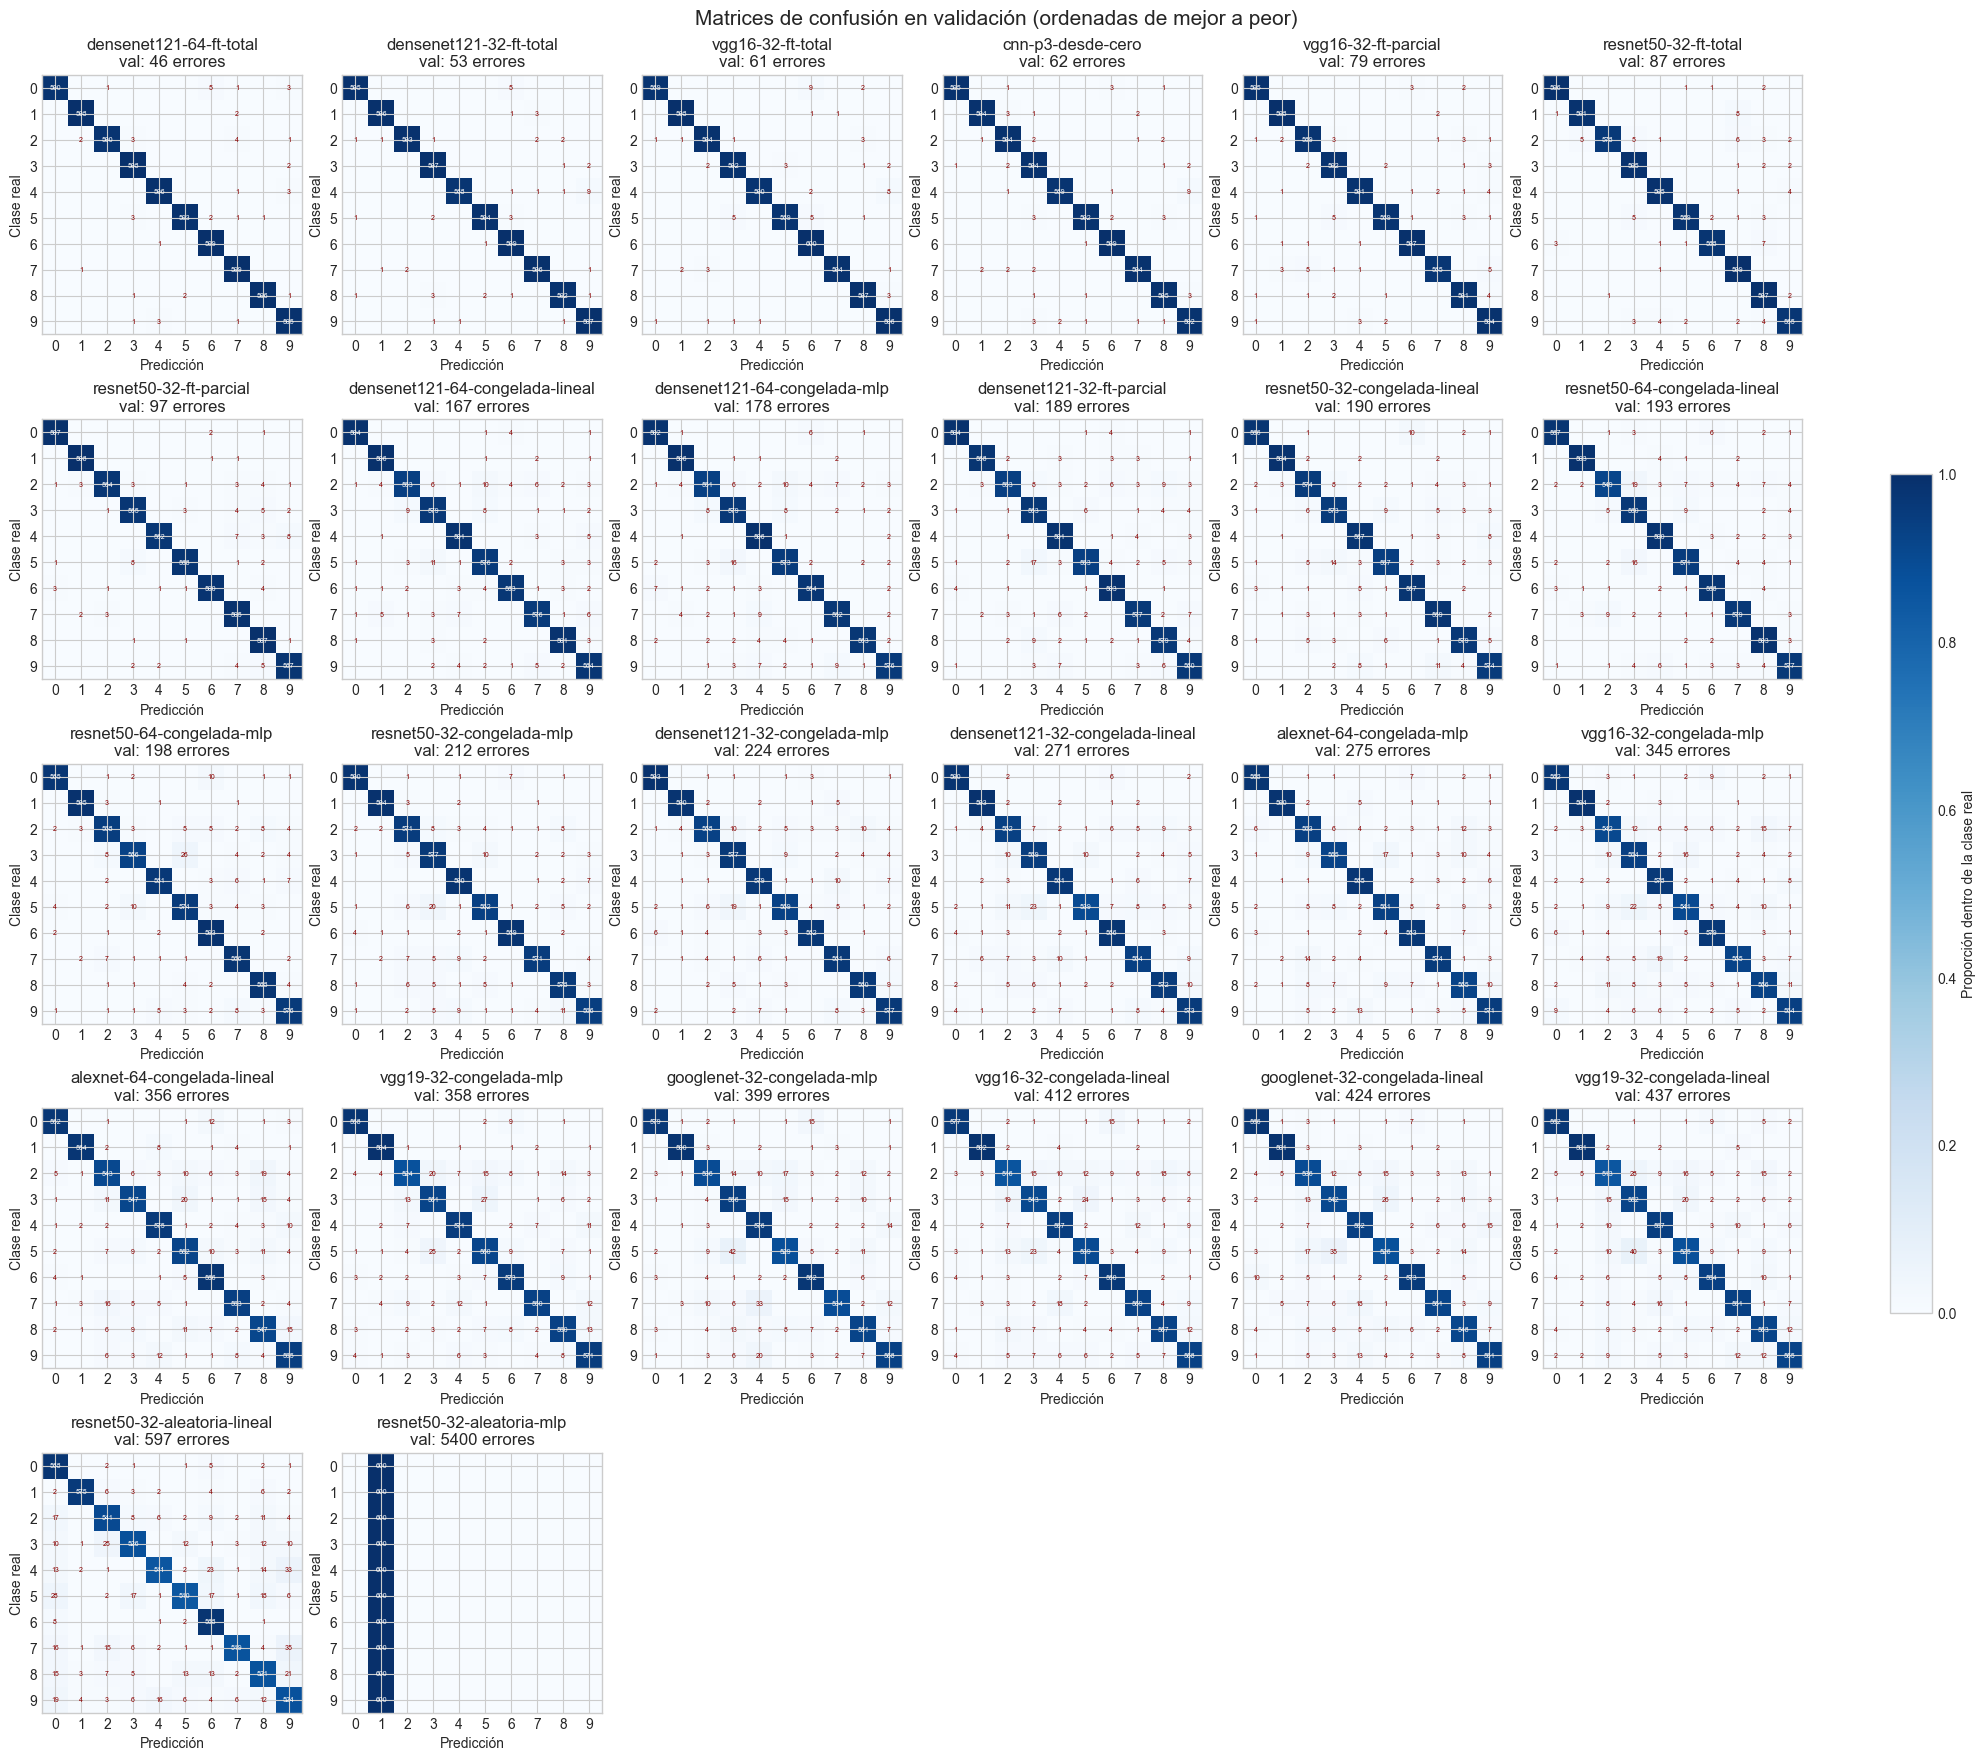

,configuration,confusión 1,confusión 2,confusión 3
0,densenet121-64-ft-total,0→6 (5),2→7 (4),4→9 (3)
1,densenet121-32-ft-total,4→9 (9),0→6 (5),5→6 (3)
2,vgg16-32-ft-total,0→6 (9),4→9 (8),5→3 (5)
3,cnn-p3-desde-cero,4→9 (9),9→3 (3),1→2 (3)
4,vgg16-32-ft-parcial,7→9 (5),5→3 (5),7→2 (5)
5,resnet50-32-ft-total,1→7 (8),6→8 (7),2→7 (6)
6,resnet50-32-ft-parcial,4→9 (8),5→3 (8),4→7 (7)
7,densenet121-64-congelada-lineal,5→3 (11),2→5 (10),3→2 (9)
8,densenet121-64-congelada-mlp,5→3 (16),2→5 (10),7→4 (9)
9,densenet121-32-ft-parcial,5→3 (17),2→8 (9),8→3 (9)


In [13]:
def draw_confusion_matrix(ax, matrix, title, fontsize=6):
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ax.set(title=title, xlabel='Predicción', ylabel='Clase real', xticks=CLASSES, yticks=CLASSES)
    for i in CLASSES:
        for j in CLASSES:
            if matrix[i, j]:
                ax.text(j, i, matrix[i, j], ha='center', va='center', fontsize=fontsize,
                        color='white' if normalized[i, j] > 0.5 else 'darkred')
    return image


names = list(results_df['configuration'])
columns = 6
rows = int(np.ceil(len(names) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(columns * 3.3, rows * 3.5), layout='constrained')
for ax, name in zip(axes.flat, names):
    row = results_df.set_index('configuration').loc[name]
    image = draw_confusion_matrix(ax, confusion_matrices[f'{name}_val'],
                                  f"{name}\nval: {row['val_errors']} errores", fontsize=5)
for ax in axes.flat[len(names):]:
    ax.axis('off')
fig.colorbar(image, ax=axes, shrink=0.5, label='Proporción dentro de la clase real')
fig.suptitle('Matrices de confusión en validación (ordenadas de mejor a peor)', fontsize=15)
plt.show()

top_confusions = []
for name in names:
    matrix = confusion_matrices[f'{name}_val'].copy()
    np.fill_diagonal(matrix, 0)
    pairs = np.dstack(np.unravel_index(np.argsort(matrix, axis=None)[::-1][:3], matrix.shape))[0]
    top_confusions.append({'configuration': name, **{
        f'confusión {k + 1}': f'{i}→{j} ({matrix[i, j]})' for k, (i, j) in enumerate(pairs)
    }})
display(pd.DataFrame(top_confusions))

## 5. Modelo seleccionado: evaluación final y persistencia

El código intenta primero exportar el mejor modelo con `torch.export` (`.pt2`). Con el modelo ganador falló (`UserError`, como se ve en la salida de la sección 3.2), así que se usó la alternativa prevista: un grafo **TorchScript** generado con `torch.jit.trace` y guardado como `mejor_modelo_transfer_mnist.pt`. Ambos formatos se pueden ejecutar sin el código fuente de las clases. Se recarga el fichero, se comprueba que reproduce exactamente su resultado de validación (en CPU) y solo entonces se evalúa en test. A continuación se muestran, a título **informativo**, las métricas de test de todas las configuraciones para comprobar si la ordenación por validación se mantiene en datos nunca vistos. Estos valores no se han utilizado para elegir el modelo.

/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Mejor configuración: densenet121-64-ft-total
Parámetros: 7,218,826
Entrenamiento: exactitud=99.6796%; errores=173/54000
Validación:    exactitud=99.2333%; errores=46/6000
Test:          exactitud=99.2400%; errores=76/10000
Tiempo total: 543.5 s (5 épocas, pesos de la época 3)
Modelo exportado en: /Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-2-RNN-Convolucionales/Practica-4/mejor_modelo_transfer_mnist.pt


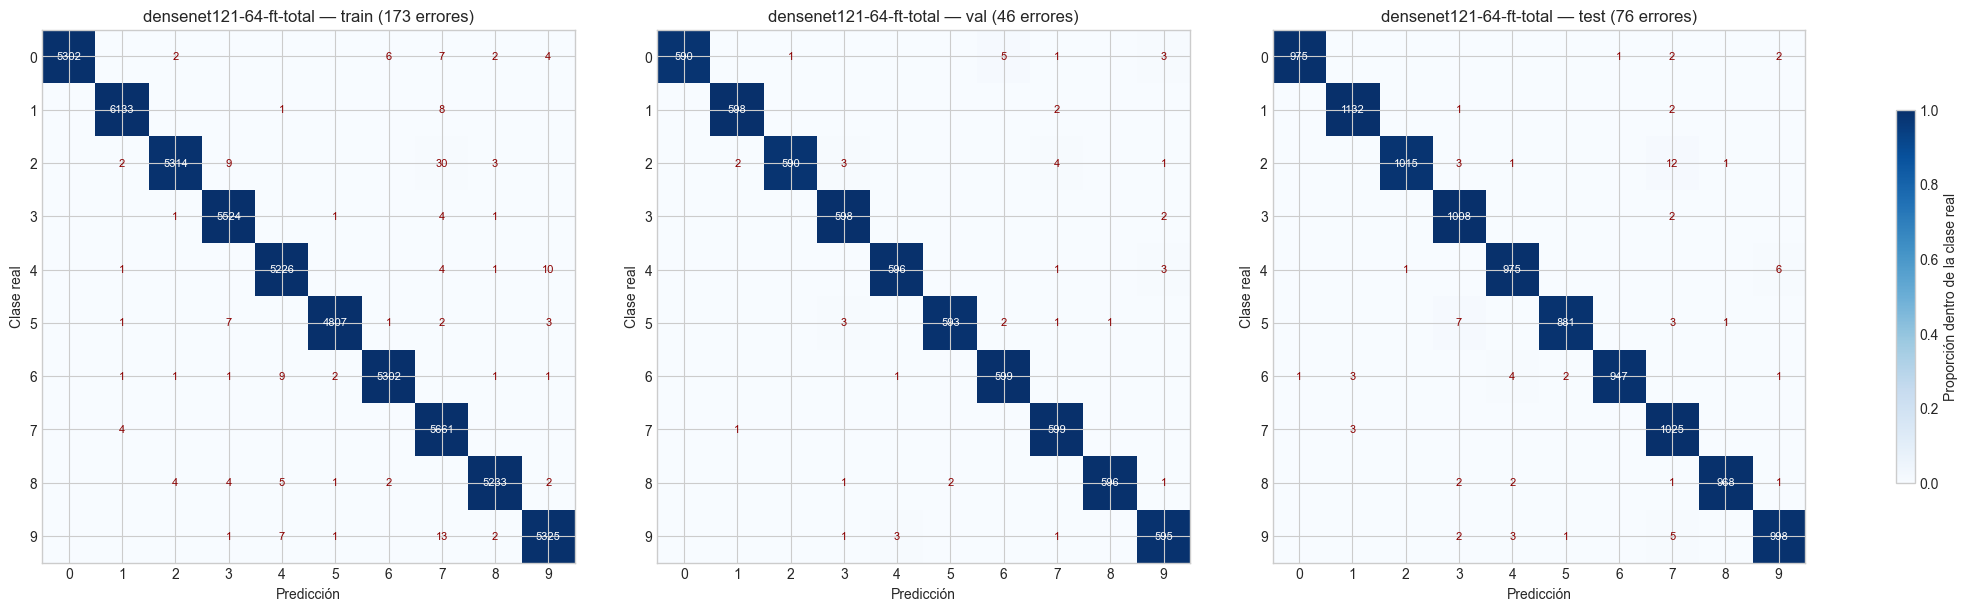

dígito,0,1,2,3,4,5,6,7,8,9
ejemplos,980.000000,1135.000000,1032.000000,1010.000000,982.000000,892.000000,958.000000,1028.000000,974.000000,1009.000000
errores,5.000000,3.000000,17.000000,2.000000,7.000000,11.000000,11.000000,3.000000,6.000000,11.000000
exactitud,0.9949,0.9974,0.9835,0.9980,0.9929,0.9877,0.9885,0.9971,0.9938,0.9891


In [14]:
if model_path.suffix == '.pt2':
    best_model = torch.export.load(str(model_path)).module()
else:
    best_model = torch.jit.load(str(model_path))
best_model.eval()
best_row = eligible.iloc[0]
reloaded_accuracy, reloaded_errors, _, _ = evaluate_predictions(best_model, x_val, y_val, 'cpu')
if not np.isclose(reloaded_accuracy, best_row['val_accuracy']) or reloaded_errors != best_row['val_errors']:
    raise RuntimeError('El modelo recuperado no reproduce el resultado de validación')

test_accuracy, test_errors, test_matrix, test_predictions = evaluate_predictions(best_model, x_test, y_test, 'cpu')
assert test_errors == test_results[best_name][1]
confusion_matrices[f'{best_name}_test'] = test_matrix
np.savez_compressed(BASE_DIR / 'matrices_confusion.npz', **confusion_matrices)

results_df['test_accuracy'] = results_df['configuration'].map(lambda name: test_results[name][0])
results_df['test_errors'] = results_df['configuration'].map(lambda name: test_results[name][1])
results_df.to_csv(BASE_DIR / 'resultados_configuraciones.csv', index=False)

print('Mejor configuración:', best_name)
print(f"Parámetros: {best_row['total_parameters']:,}")
print(f"Entrenamiento: exactitud={best_row['train_accuracy']:.4%}; errores={best_row['train_errors']}/{len(y_fit)}")
print(f'Validación:    exactitud={reloaded_accuracy:.4%}; errores={reloaded_errors}/{len(y_val)}')
print(f'Test:          exactitud={test_accuracy:.4%}; errores={test_errors}/{len(y_test)}')
print(f"Tiempo total: {best_row['total_seconds']:.1f} s ({best_row['epochs_run']} épocas, pesos de la época {best_row['restored_epoch']})")
print('Modelo exportado en:', model_path.resolve())

fig, axes = plt.subplots(1, 3, figsize=(20, 6), layout='constrained')
for ax, split in zip(axes, ('train', 'val', 'test')):
    matrix = confusion_matrices[f'{best_name}_{split}']
    image = draw_confusion_matrix(ax, matrix, f'{best_name} — {split} ({matrix.sum() - np.trace(matrix)} errores)', fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.7, label='Proporción dentro de la clase real')
plt.show()

per_class = pd.DataFrame({'ejemplos': np.bincount(y_test.numpy(), minlength=10),
                          'errores': np.bincount(y_test.numpy()[test_predictions != y_test.numpy()], minlength=10)})
per_class['exactitud'] = 1 - per_class['errores'] / per_class['ejemplos']
display(per_class.rename_axis('dígito').T.style.format('{:.4f}', subset=pd.IndexSlice[['exactitud'], :]))

,configuration,seleccionable,total_parameters,val_accuracy,val_errors,test_accuracy,test_errors,rank_val,rank_test
0,densenet121-64-ft-total,True,"7,218,826",99.233%,46,99.240%,76,1,2
1,densenet121-32-ft-total,True,"7,218,826",99.117%,53,99.350%,65,2,1
2,vgg16-32-ft-total,True,"14,848,586",98.983%,61,99.230%,77,3,3
3,cnn-p3-desde-cero,False,"468,394",98.967%,62,99.180%,82,4,4
4,vgg16-32-ft-parcial,True,"14,848,586",98.683%,79,98.730%,127,5,5
5,resnet50-32-ft-total,True,"24,035,146",98.550%,87,98.690%,131,6,6
6,resnet50-32-ft-parcial,True,"24,035,146",98.383%,97,98.280%,172,7,7
7,densenet121-64-congelada-lineal,True,"6,964,106",97.217%,167,97.140%,286,8,11
8,densenet121-64-congelada-mlp,True,"7,218,826",97.033%,178,97.040%,296,9,12
9,densenet121-32-ft-parcial,True,"7,218,826",96.850%,189,97.000%,300,10,13


Correlación de Spearman entre el orden de validación y el de test (configuraciones seleccionables): 0.971


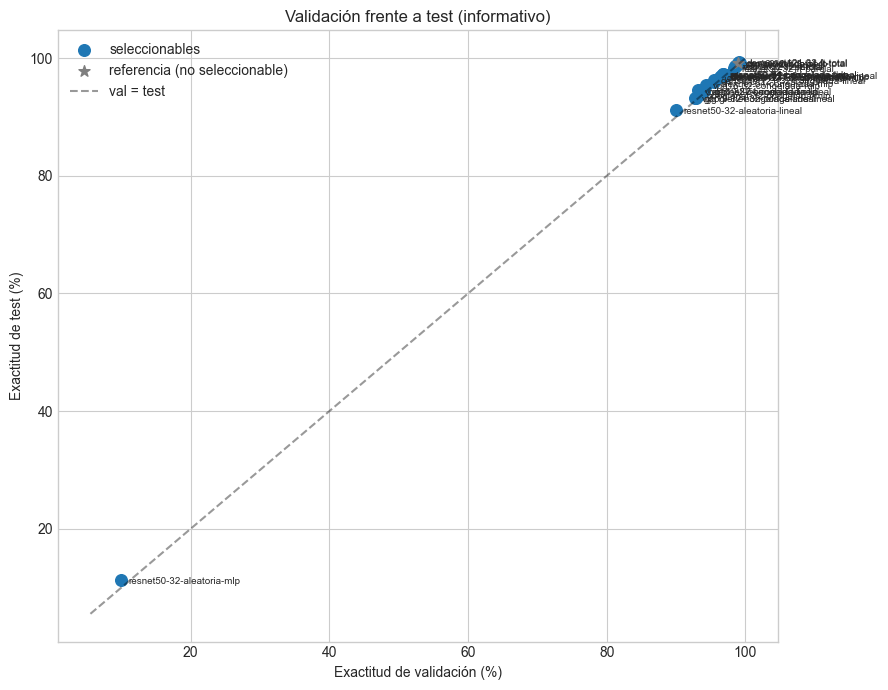

In [15]:
comparison = results_df[['configuration', 'seleccionable', 'total_parameters',
                         'val_accuracy', 'val_errors', 'test_accuracy', 'test_errors']].copy()
comparison['rank_val'] = np.arange(1, len(comparison) + 1)
comparison['rank_test'] = comparison['test_accuracy'].rank(ascending=False, method='min').astype(int)
display(comparison.style.format({'total_parameters': '{:,}', 'val_accuracy': '{:.3%}', 'test_accuracy': '{:.3%}'}))
spearman = comparison.loc[comparison['seleccionable'], ['val_accuracy', 'test_accuracy']].corr(method='spearman').iloc[0, 1]
print(f'Correlación de Spearman entre el orden de validación y el de test (configuraciones seleccionables): {spearman:.3f}')

fig, ax = plt.subplots(figsize=(9, 7))
for selectable, marker, color in ((True, 'o', 'tab:blue'), (False, '*', 'tab:gray')):
    sub = comparison[comparison['seleccionable'] == selectable]
    ax.scatter(sub['val_accuracy'] * 100, sub['test_accuracy'] * 100, marker=marker, s=70,
               color=color, label='seleccionables' if selectable else 'referencia (no seleccionable)')
for _, row in comparison.iterrows():
    ax.annotate(row['configuration'], (row['val_accuracy'] * 100, row['test_accuracy'] * 100),
                fontsize=7, xytext=(5, -3), textcoords='offset points')
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), 100]
ax.plot(lims, lims, 'k--', alpha=0.4, label='val = test')
ax.set(xlabel='Exactitud de validación (%)', ylabel='Exactitud de test (%)',
       title='Validación frente a test (informativo)')
ax.legend()
plt.tight_layout()
plt.show()

### Dónde se equivoca el modelo

Se muestra una muestra de los errores de test del mejor modelo con la probabilidad *softmax* asignada a la predicción. Muchos de ellos son grafías ambiguas incluso para una persona.

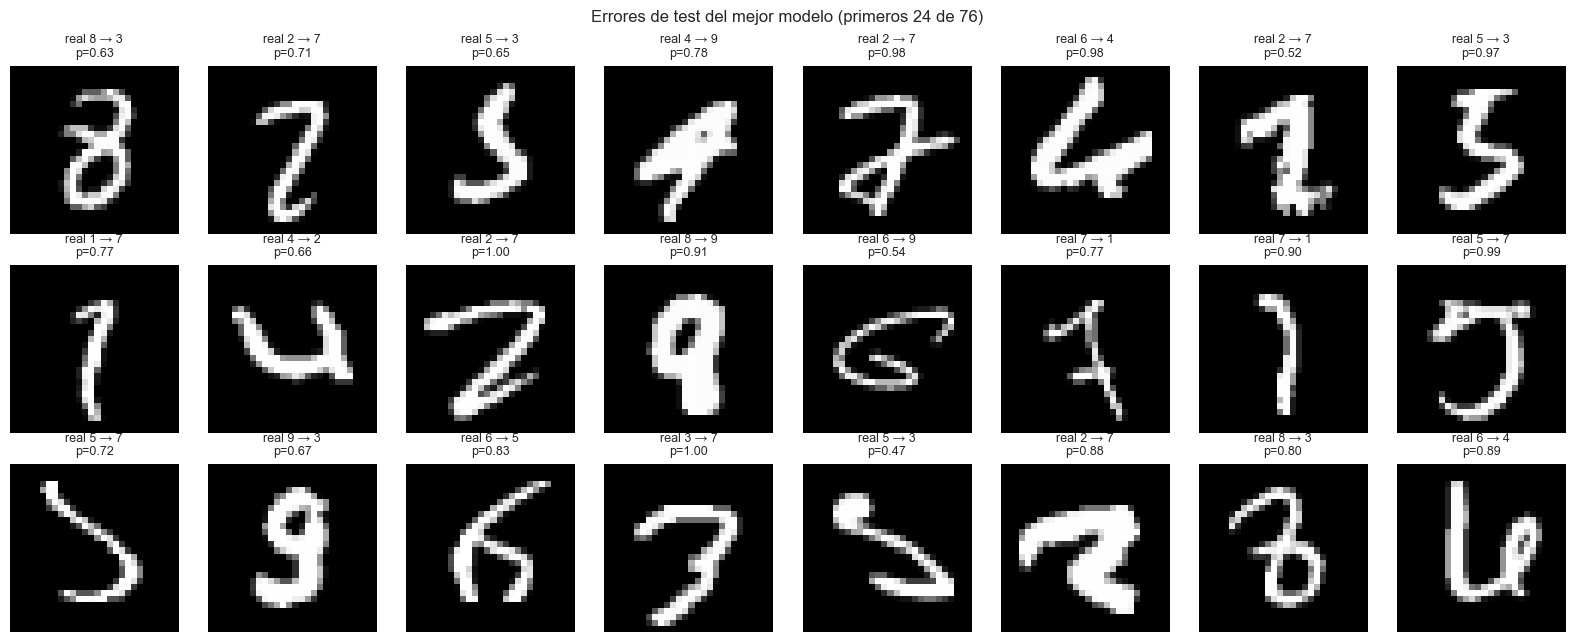

In [16]:
probabilities = torch.softmax(forward_batches(best_model, x_test, 'cpu'), dim=1)
wrong = np.flatnonzero(test_predictions != y_test.numpy())
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, index in zip(axes.flat, wrong):
    ax.imshow(x_test[index, 0].numpy(), cmap='gray')
    ax.set_title(f'real {int(y_test[index])} → {test_predictions[index]}\np={probabilities[index].max():.2f}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle(f'Errores de test del mejor modelo (primeros {min(len(wrong), axes.size)} de {len(wrong)})')
plt.tight_layout()
plt.show()

### Reutilización del modelo guardado

El fichero `mejor_modelo_transfer_mnist.pt` (TorchScript) se carga con `torch.jit.load` en otro programa sin disponer del código fuente de las clases. Toda la adaptación de la entrada (redimensionado, réplica del canal de gris y normalización ImageNet) está dentro del grafo guardado. La entrada debe ser `float32` con forma `(n, 1, 28, 28)` y valores en $[0,1]$, exactamente igual que aquí. La salida son los diez *logits*; se aplica `softmax` si se quieren probabilidades.

In [17]:
if (BASE_DIR / 'mejor_modelo_transfer_mnist.pt2').exists():
    reused_model = torch.export.load(str(BASE_DIR / 'mejor_modelo_transfer_mnist.pt2')).module()
else:
    reused_model = torch.jit.load(str(BASE_DIR / 'mejor_modelo_transfer_mnist.pt'))
new_images = images_test[:8]
predicted = forward_batches(reused_model, preprocess(new_images), 'cpu').argmax(dim=1).numpy()
print('Predicción:', predicted)
print('Real:      ', digits_test[:8])

Predicción: [7 2 1 0 4 1 4 9]
Real:       [7 2 1 0 4 1 4 9]


/Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-1-Intro-RNN/.venv/lib/python3.13/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## 6. Interpretación y conclusiones

| # | Configuración | Parámetros (entrenados) | Épocas (pesos usados) | Exactitud train | Exactitud val | Errores val | Errores test* | Tiempo |
|:-:|:--|--:|--:|--:|--:|--:|--:|--:|
| 1 | **`densenet121-64-ft-total`** | **7 218 826 (7 135 178)** | **5 (3)** | **99,680 %** | **99,233 %** | **46** | **76** | **544 s** |
| 2 | `densenet121-32-ft-total` | 7 218 826 (7 135 178) | 5 (4) | 99,687 % | 99,117 % | 53 | 65 | 231 s |
| 3 | `vgg16-32-ft-total` | 14 848 586 (14 848 586) | 4 (2) | 99,559 % | 98,983 % | 61 | 77 | 271 s |
| — | `cnn-p3-desde-cero` (referencia) | 468 394 | 10 (7) | 99,389 % | 98,967 % | 62 | 82 | 363 s (CPU) |
| 4 | `vgg16-32-ft-parcial` | 14 848 586 (7 213 322) | 5 (4) | 99,435 % | 98,683 % | 79 | 127 | 122 s |
| 5 | `resnet50-32-ft-total` | 24 035 146 (23 982 026) | 3 (1) | 98,913 % | 98,550 % | 87 | 131 | 296 s |
| 6 | `resnet50-32-ft-parcial` | 24 035 146 (15 469 322) | 5 (3) | 99,089 % | 98,383 % | 97 | 172 | 334 s |
| 7 | `densenet121-64-congelada-lineal` | 6 964 106 (10 250) | 25 (22) | 98,407 % | 97,217 % | 167 | 286 | 60 s |
| 8 | `densenet121-32-ft-parcial` | 7 218 826 (2 394 890) | 5 (3) | 98,311 % | 96,850 % | 189 | 300 | 110 s |
| 9 | `resnet50-32-congelada-lineal` | 23 528 522 (20 490) | 23 (20) | 98,396 % | 96,833 % | 190 | 279 | 53 s |
| … | (resto de bases congeladas, ver tabla de la sección 4) | | | | 92,7 – 97,0 % | 178 – 437 | | |
| 25 | `resnet50-32-aleatoria-lineal` | 23 528 522 (20 490) | 11 (8) | 91,050 % | 90,050 % | 597 | 878 | 46 s |
| 26 | `resnet50-32-aleatoria-mlp` | 24 035 146 (527 114) | 4 (1) | 11,374 % | 10,000 % | 5 400 | 8 865 | 48 s |

\* El test es informativo: no se ha usado para elegir. Validación: 6 000 imágenes; test: 10 000. Los tiempos de las configuraciones congeladas incluyen la extracción de características más el entrenamiento de la cabeza; los del ajuste fino, solo el ajuste fino (la cabeza de partida es la de la fase A). Todo se ha medido en la GPU de un Apple M3 (MPS), salvo la referencia de la práctica 3, que se entrenó en CPU. Los tiempos son solo orientativos. La ejecución completa del cuaderno ha durado unos 51 minutos.

### Efecto de cada elemento (comparaciones por pares)

1. **Pesos de ImageNet frente a pesos aleatorios (ResNet50, 32 px, base congelada).** Con la misma arquitectura y la misma cabeza lineal, los pesos de ImageNet reducen los errores de validación de 597 a 190. Con la cabeza MLP, la base aleatoria **no aprende nada**: predice siempre la misma clase (exactamente 600 aciertos de 6 000, un 10 %) y la parada temprana se queda con la época 1. La causa es que, sin entrenar, las 50 capas con BatchNorm usando sus estadísticas iniciales (media 0, varianza 1) producen vectores casi idénticos para todas las imágenes. En una comprobación aparte con 512 imágenes, la desviación entre imágenes de cada característica era solo un 10 % de su valor medio, frente a un 80 % con los pesos de ImageNet. La cabeza lineal todavía aprovecha esas pequeñas diferencias; la MLP con ReLU y Adam $10^{-3}$ se hunde en la solución constante. Lo que se transfiere, por tanto, son **filtros útiles** (bordes, trazos, texturas), no solo una arquitectura.
2. **Base congelada: qué modelo (32 px, cabeza MLP).** ResNet50 (212 errores) y DenseNet121 (224) dan las mejores características, seguidas de VGG16 (345), VGG19 (358) y GoogLeNet (399). Las redes con conexiones residuales o densas combinan rasgos de varios niveles en el vector final. VGG solo entrega los 512 mapas de su último bloque, que a 32 px ocupan 1×1 píxel. VGG19 no mejora a VGG16: más profundidad sin adaptar a MNIST solo añade especialización en ImageNet. AlexNet, que necesita 64 px (a 32 px sus mapas se reducen a tamaño 0), llega a 275 errores con solo 2,5 millones de parámetros.
3. **Resolución 32 frente a 64 px.** En DenseNet121 congelada, pasar a 64 px reduce los errores de 271 a 167 (lineal) y de 224 a 178 (MLP). En ResNet50 casi no cambia nada (190 → 193 y 212 → 198). Con el ajuste fino total de DenseNet121, la validación mejora de 53 a 46 errores, pero en test ocurre lo contrario (65 frente a 76) y el coste se multiplica por 2,4 (231 → 544 s). A 32 px las últimas etapas de estas redes trabajan sobre mapas de 1×1 o 2×2 y desaprovechan su campo receptivo. Ampliar la imagen ayuda a la base congelada, pero una vez que se ajusta toda la red la ventaja es pequeña y no concluyente.
4. **Cabeza lineal frente a MLP.** La capa oculta de 256 neuronas ayuda cuando las características son pobres (VGG16 412 → 345, VGG19 437 → 358, AlexNet 356 → 275, DenseNet121 a 32 px 271 → 224). Con ResNet50 y con DenseNet121 a 64 px empeora ligeramente (190 → 212; 167 → 178): esas características ya son casi linealmente separables y la MLP solo añade varianza. Las cabezas lineales sobre VGG y GoogLeNet agotaron las 30 épocas sin converger del todo.
5. **Congelada → ajuste fino parcial → ajuste fino total.** Es el factor que más influye en el resultado:

   | Base (32 px) | Congelada (MLP) | FT parcial | FT total |
   |:--|--:|--:|--:|
   | VGG16 | 345 | 79 (bloque 5) | **61** |
   | ResNet50 | 212 | 97 (`layer4`) | 87 |
   | DenseNet121 | 224 | 189 (`denseblock4`) | **53** |

   Las imágenes de ImageNet son fotografías a color y los dígitos son trazos grises de baja resolución, de modo que las capas altas, especializadas en objetos de ImageNet, no sirven tal cual. Ajustarlas reduce los errores entre un 59 % y un 82 %. El ajuste parcial funciona bien en VGG16, cuyo bloque 5 aún trabaja con mapas de 2×2. En DenseNet121 apenas mejora, porque su último bloque denso trabaja sobre mapas de 1×1 y no puede reaprender patrones espaciales. Con la red entera DenseNet121 pasa a ser la mejor.
6. **ResNet50 es la peor en ajuste fino** pese a ser la mejor congelada a 32 px y la más grande (24 millones de parámetros). En el ajuste total, la pérdida de validación es mínima ya en la **primera época** y luego sube, por lo que la parada temprana se detiene en la época 3. Con una tasa de $10^{-4}$ y las BatchNorm congeladas con estadísticas de ImageNet, 24 millones de parámetros se desajustan rápido. Probablemente necesitaría una tasa menor (p. ej. $10^{-5}$) o descongelar también BatchNorm, pero eso no se ha comprobado. DenseNet121, con 3,3 veces menos parámetros y reutilización de características entre capas, es la que mejor se adapta.
7. **Transfer learning frente a la CNN de la práctica 3.** Solo los tres mejores modelos ajustados por completo igualan o superan a la CNN entrenada desde cero (62 errores de validación y 82 de test). La extracción de características con la base congelada queda muy lejos (≥ 167 errores). La ganadora reduce los errores de validación un 26 % (46 frente a 62) y los de test un 7 % (76 frente a 82), a cambio de 15 veces más parámetros y de necesitar GPU para entrenar en un tiempo razonable.

### ¿Qué configuración obtiene el mejor rendimiento?

Según el criterio fijado de antemano (exactitud de validación), la mejor configuración es **`densenet121-64-ft-total`**:

- entrada MNIST `(1, 28, 28)` en $[0,1]$ → redimensionado bilineal a 64×64 → réplica del canal gris en 3 canales → normalización con la media y la desviación de ImageNet (todo dentro del modelo);
- base **DenseNet121** con pesos `IMAGENET1K_V1`, todas sus capas convolucionales entrenables y sus BatchNormalization congeladas en modo inferencia → *global average pooling* (1 024 características);
- cabeza `Linear(1024, 256)` → ReLU → `Dropout(0,5)` → `Linear(256, 10)`;
- entrenamiento en dos etapas: primero solo la cabeza sobre características congeladas (Adam $10^{-3}$, lote 128, 12 épocas, pesos de la época 9) y después ajuste fino de toda la red (Adam $10^{-4}$, lote 128, 5 épocas, pesos de la época 3).

Resultados: **99,233 % en validación (46 errores de 6 000)** y **99,24 % en test (76 errores de 10 000)**. La brecha entre entrenamiento y validación es de solo 0,45 puntos. En test, el dígito con más errores es el 2 (17), seguido del 5, el 6 y el 9 (11 cada uno). La confusión más frecuente es 2 → 7 (12 casos), seguida de 5 → 3 (7), 4 → 9 (6) y 9 → 7 (5), grafías que se parecen.

Matices:

- **Empate técnico entre los tres primeros y la referencia.** En test, `densenet121-32-ft-total` comete menos errores (65) que la ganadora (76), y `vgg16-32-ft-total` (77) queda prácticamente igual. Diferencias de una decena de imágenes entre 10 000 están dentro de la variación debida a la semilla y a la muestra. La ordenación por validación y por test es muy parecida (correlación de Spearman 0,97) y la selección no se ha cambiado mirando el test.
- **Rendimiento frente a coste.** `densenet121-32-ft-total` ofrece casi la misma exactitud en menos de la mitad de tiempo (231 frente a 544 s) y es la mejor en test. Si importa el tamaño del modelo, la CNN de la práctica 3 (0,47 millones de parámetros) sigue siendo muy competitiva: MNIST es un problema sencillo y lejano a ImageNet, y aquí el preentrenamiento aporta menos que en problemas con pocas imágenes o más parecidos a fotografías.
- **Limitaciones:** una única semilla, y en MPS la ejecución no es reproducible bit a bit. El ajuste fino tiene como máximo 5 épocas (la DenseNet121 a 32 px usó los pesos de la época 4 de 5, así que con más épocas quizá habría mejorado). La tasa de aprendizaje es fija y no hay aumento de datos. Solo se han probado 32 y 64 px, lejos de los 224 px nativos de estas redes. Para afirmar con seguridad que una configuración es mejor habría que repetir con varias semillas y explorar la tasa de aprendizaje, sobre todo en ResNet50.

El modelo se ha guardado en **`mejor_modelo_transfer_mnist.pt`** (TorchScript, 30 MB). Recibe tensores `float32` de forma `(n, 1, 28, 28)` con valores en $[0,1]$ y devuelve los diez *logits* (aplicar `softmax` para obtener probabilidades). La tabla completa está en `resultados_configuraciones.csv`, y las matrices de confusión de entrenamiento y validación de todas las configuraciones, más la de test del ganador, en `matrices_confusion.npz`.